In [1]:
import os
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

---
### Exploration des images :

#### Fonctions

In [2]:
from pathlib import Path

dataset_dir = ""

def verif_image(dataset_dir):
    image_paths = [p for p in dataset_dir.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}]

    images_info = []
    for image_path in image_paths:
        with Image.open(image_path) as img:
            images_info.append({
                "fichier": image_path.name,
                "classe": image_path.parent.name,
                "taille": img.size,
                "mode": img.mode,
            })

    df_images = pd.DataFrame(images_info)
    print("Nombre d'images :", len(df_images))    
    print(df_images["classe"].value_counts())
    print(df_images.to_string())

# Afficher un échantillon 5x5
def show_samples(dataset_dir):
    # Récupérer les fichiers PNG uniquement
    image_paths = list(dataset_dir.glob("*.jpg"))
    print(image_paths)
    fig, ax = plt.subplots(5,5, figsize=(15,15))
    for i, path in enumerate(image_paths[:25]):  # on prend juste les 9 premières
        img = Image.open(path)
        ax[i//5, i%5].imshow(img, cmap='gray')
        ax[i//5, i%5].axis('off')
    plt.show()

#### Label + cancer

Nombre d'images : 50
classe
cancer    50
Name: count, dtype: int64
                                     fichier  classe      taille mode
0   05340cd4-3bb2-459d-9937-bf27d52d8351.jpg  cancer  (512, 512)  RGB
1   0c6f3641-60d9-4a76-abe5-de89d55d5f2c.jpg  cancer  (512, 512)  RGB
2   0f718241-8f63-4b55-81ce-315324b51069.jpg  cancer  (512, 512)  RGB
3   11a7a426-4806-401e-98b2-b96e7094d1a6.jpg  cancer  (512, 512)  RGB
4   1c043dbb-4623-4769-8e5e-0223bd745040.jpg  cancer  (512, 512)  RGB
5   27149ff6-8363-4942-a72a-eb7e38e77099.jpg  cancer  (512, 512)  RGB
6   2b810835-844c-49ff-b0f1-c7a71a0c696c.jpg  cancer  (512, 512)  RGB
7   2d662cc1-509b-4657-a208-6d181aedd5e3.jpg  cancer  (512, 512)  RGB
8   2fa551e9-5b85-44f6-ab71-6035b4e3f8aa.jpg  cancer  (512, 512)  RGB
9   3c3d07cb-ec2a-43b0-b8a3-3a51573ad930.jpg  cancer  (512, 512)  RGB
10  46587a13-4250-4d3e-b930-7d7be8f96425.jpg  cancer  (512, 512)  RGB
11  4d14c944-eed4-4c4f-8fd9-cbbb53e8f35d.jpg  cancer  (512, 512)  RGB
12  5066bf9b-d944-4d40-

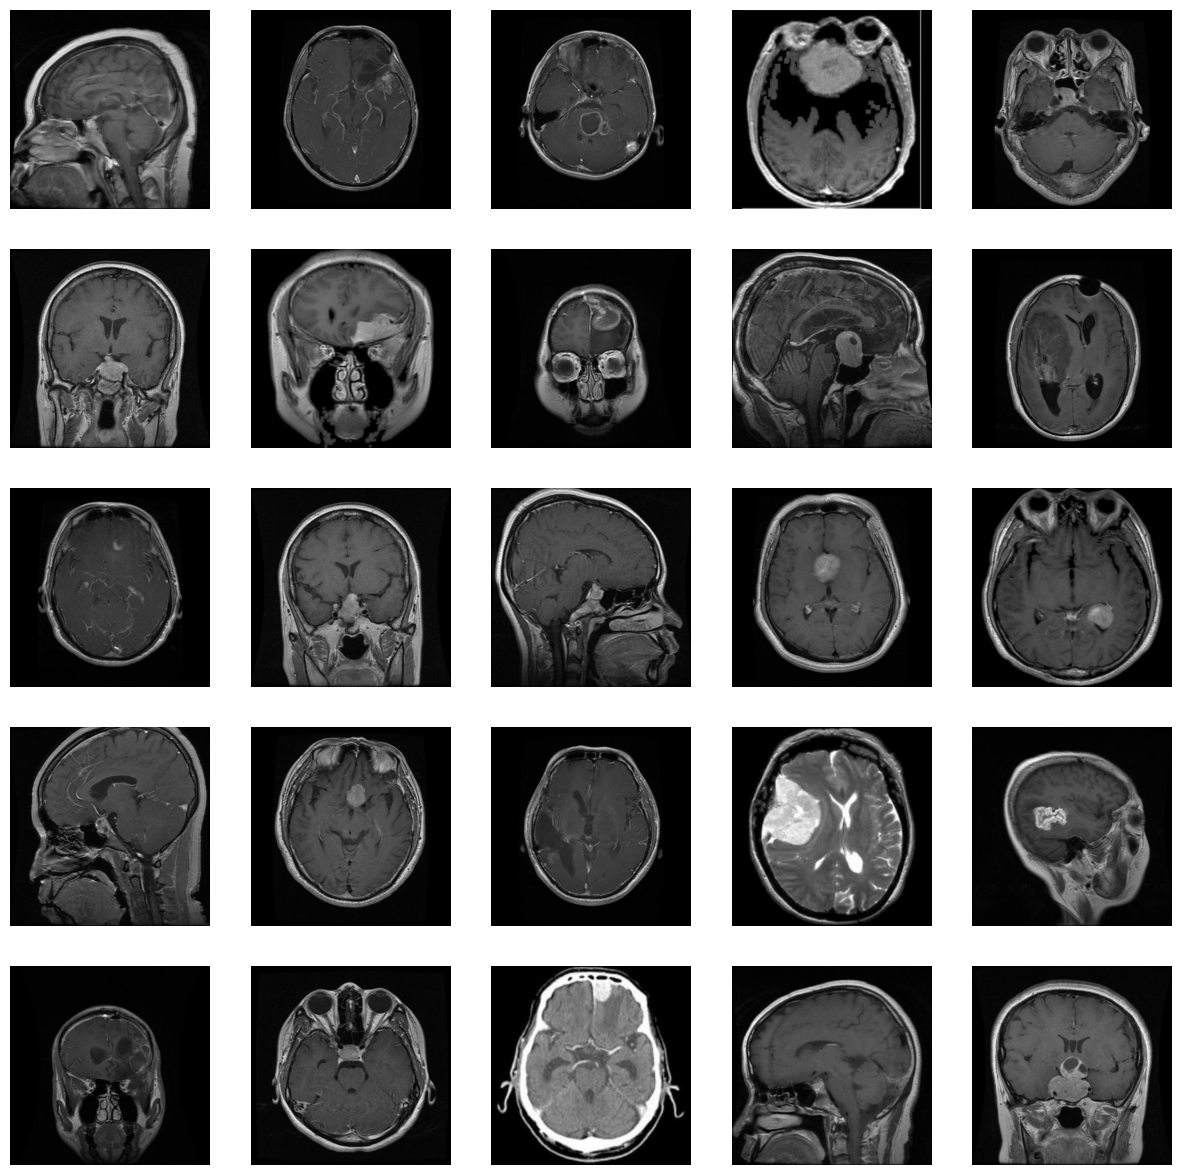

In [3]:
dir_cancer = Path("./mri_dataset_brain_cancer_oc/mri_dataset_brain_cancer_oc/avec_labels/cancer")

verif_image(dir_cancer)
show_samples(dir_cancer)


#### Label + normal

Nombre d'images : 50
classe
normal    50
Name: count, dtype: int64
                                     fichier  classe      taille mode
0   0161f9bf-fa93-4d02-8dce-84bfd49fe6a2.jpg  normal  (512, 512)  RGB
1   09316c60-86c8-4f24-934e-8d433b8b9d72.jpg  normal  (512, 512)  RGB
2   11825cf3-9b35-42d3-ac99-21f26dd2f94e.jpg  normal  (512, 512)  RGB
3   14703976-0467-4acb-ade4-8a375ebfd4f9.jpg  normal  (512, 512)  RGB
4   1953e998-29b8-4d36-975f-007c4fcb84a3.jpg  normal  (512, 512)  RGB
5   22164f5b-9b9f-4fcc-897a-9f902d730bbe.jpg  normal  (512, 512)  RGB
6   2251259e-64fd-44cd-b813-357d0a47e563.jpg  normal  (512, 512)  RGB
7   2593c9b2-36d5-433b-81bf-44ab993a795e.jpg  normal  (512, 512)  RGB
8   2794c549-1ec3-4d08-abed-84ccd53791f3.jpg  normal  (512, 512)  RGB
9   3c213abc-ab17-4037-a8e5-caa7bc1babe1.jpg  normal  (512, 512)  RGB
10  3e3f6d78-0983-46a9-8755-a67b5f3f5b20.jpg  normal  (512, 512)  RGB
11  3ebe5f3a-90d3-4e79-af97-3d9584215044.jpg  normal  (512, 512)  RGB
12  3f4cb3e9-75fc-4b40-

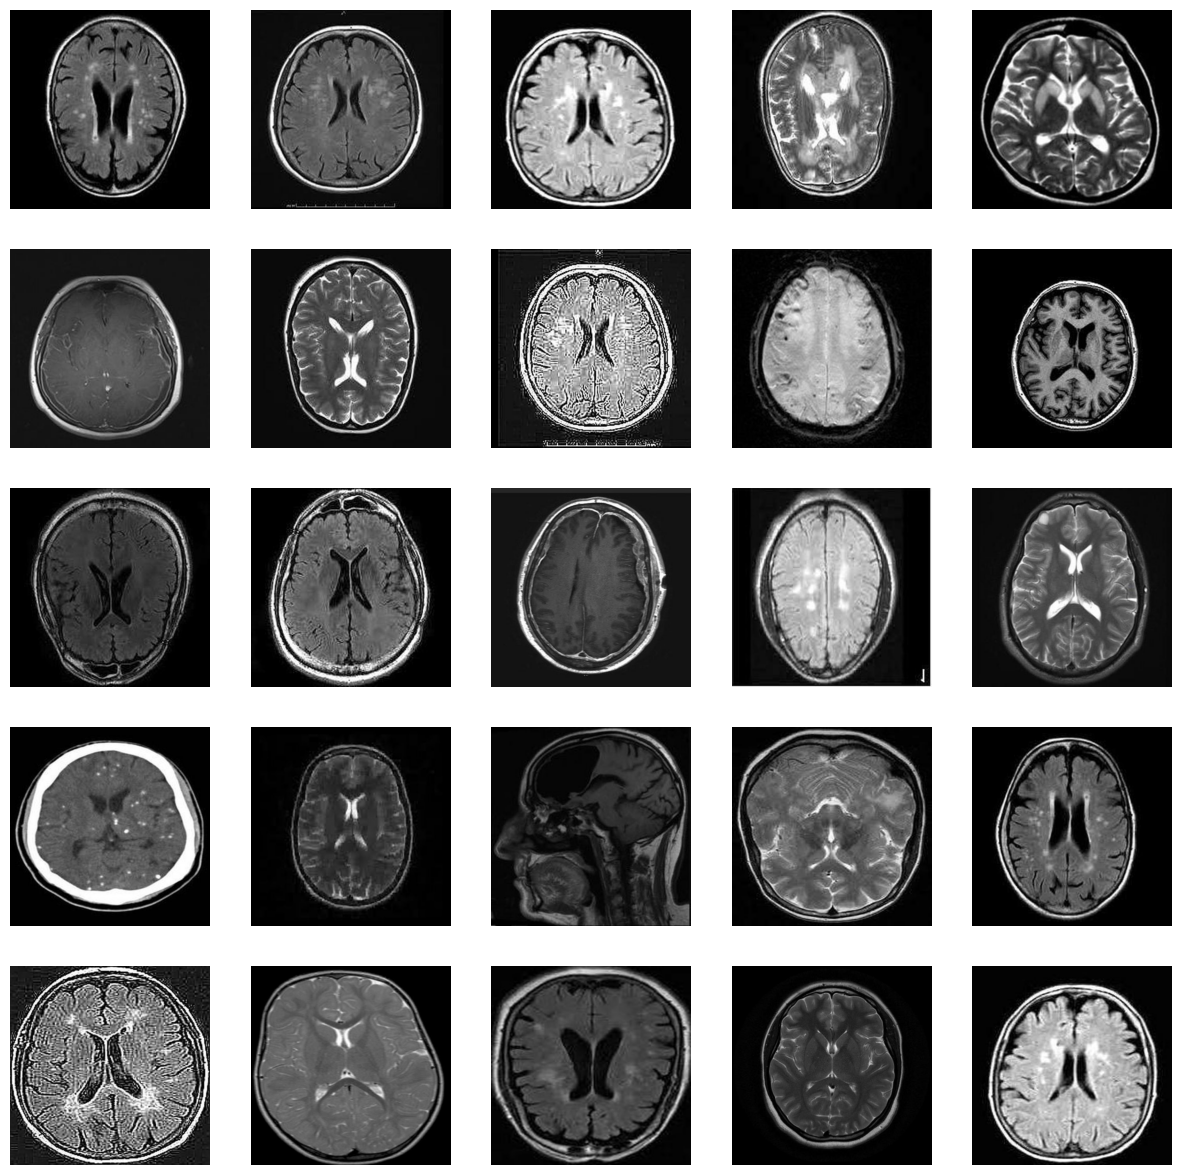

In [4]:
dir_normal = Path("./mri_dataset_brain_cancer_oc/mri_dataset_brain_cancer_oc/avec_labels/normal")

verif_image(dir_normal)
show_samples(dir_normal)

#### Sans Label

Nombre d'images : 1406
classe
sans_label    1406
Name: count, dtype: int64
                                       fichier      classe      taille mode
0     001b158a-7af8-451e-bf31-3a9116265f3a.jpg  sans_label  (512, 512)  RGB
1     00366e8d-5520-4d3c-a70b-91a7eec1f521.jpg  sans_label  (512, 512)  RGB
2     00455a62-f79f-4072-9a23-4951e759acdc.jpg  sans_label  (512, 512)  RGB
3     004ce5f5-ca6b-490f-9b2f-c322c152e2ee.jpg  sans_label  (512, 512)  RGB
4     005d9a37-8894-4eb5-8367-1015d4a43638.jpg  sans_label  (512, 512)  RGB
5     009e9d31-9f37-4d97-a941-81501294c403.jpg  sans_label  (512, 512)  RGB
6     009eac4a-c951-4da9-852a-b32e9ce20c6e.jpg  sans_label  (512, 512)  RGB
7     00e9e198-79de-47ab-9f4e-7b76152324bb.jpg  sans_label  (512, 512)  RGB
8     01274f5e-3064-4efd-af4b-38e164188c31.jpg  sans_label  (512, 512)  RGB
9     01717fbf-4bcf-475a-a718-361ed07d2854.jpg  sans_label  (512, 512)  RGB
10    01d1f0ed-5070-45a8-ad26-f8a95ebec98d.jpg  sans_label  (512, 512)  RGB
11    01d4471

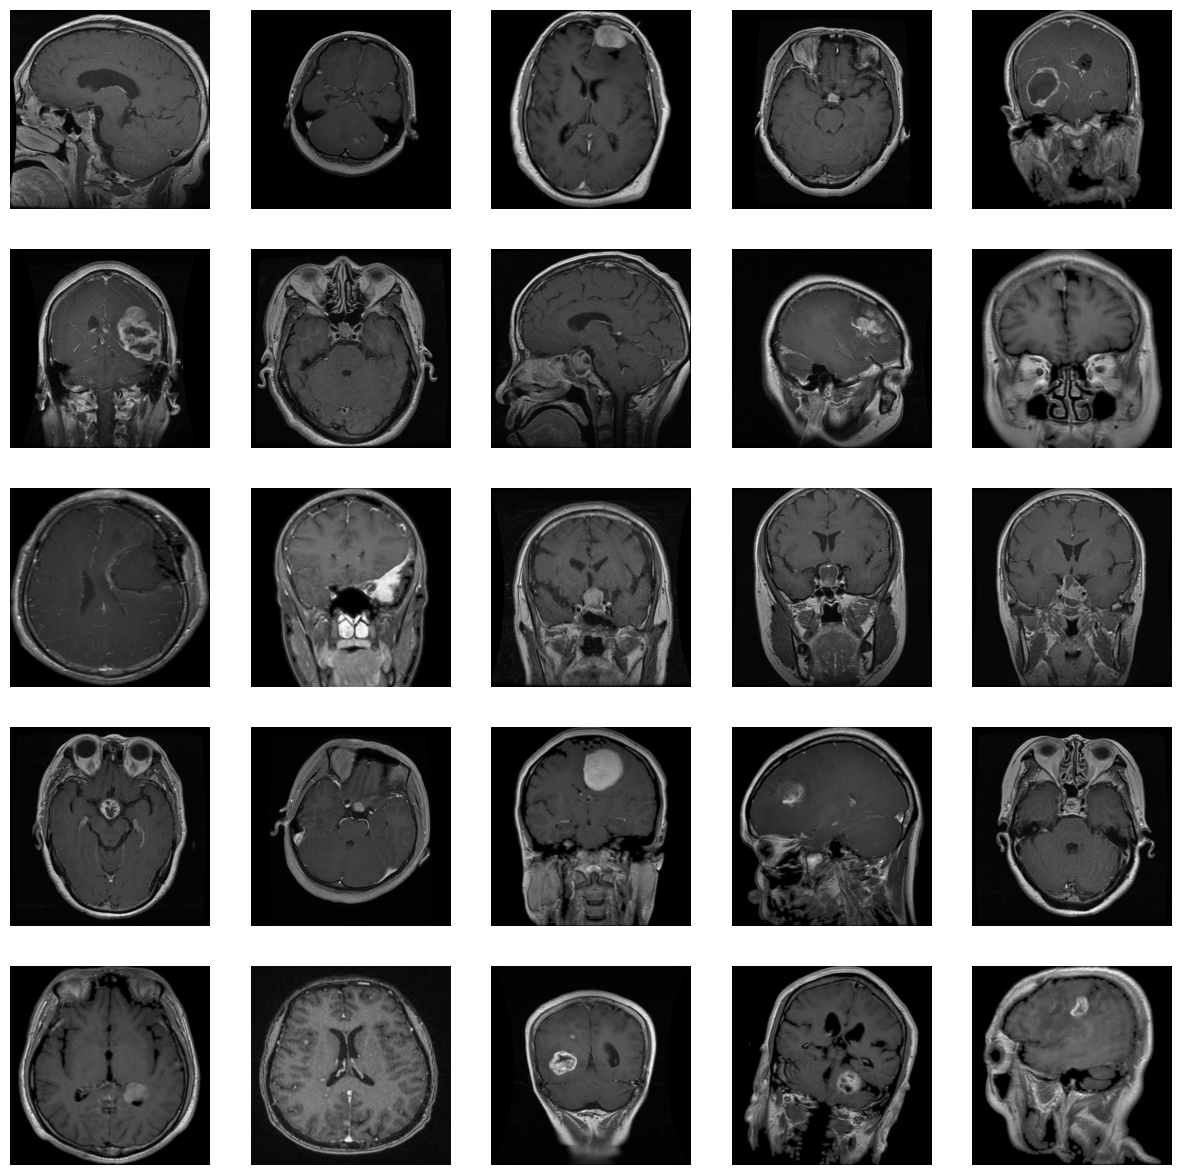

In [5]:
dir_unlabeled = Path("./mri_dataset_brain_cancer_oc/mri_dataset_brain_cancer_oc/sans_label")

verif_image(dir_unlabeled)
show_samples(dir_unlabeled)

#### Exemple Ovale avec_labels/normal

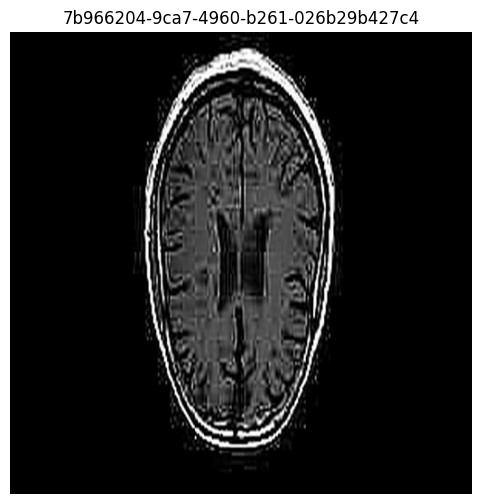

In [6]:
# Chemin vers l'image spécifique
image_path = Path("./mri_dataset_brain_cancer_oc/mri_dataset_brain_cancer_oc/avec_labels/normal/7b966204-9ca7-4960-b261-026b29b427c4.jpg")

# Ouvrir l'image
img = Image.open(image_path)

# Afficher
plt.figure(figsize=(6,6))
plt.imshow(img, cmap='gray')  # cmap='gray' pour les IRM en niveaux de gris
plt.axis('off')
plt.title(image_path.stem)
plt.show()

---
### Prétraitement

#### Transformation

In [2]:
import cv2
import numpy as np
from PIL import Image
from torchvision import transforms

# fonction d'égalisation
def equalize_histogram(img):
    img_np = np.array(img)

    if len(img_np.shape) == 3:
        img_yuv = cv2.cvtColor(img_np, cv2.COLOR_RGB2YUV)
        img_yuv[:, :, 0] = cv2.equalizeHist(img_yuv[:, :, 0])
        img_eq = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2RGB)
    else:
        img_eq = cv2.equalizeHist(img_np)

    return Image.fromarray(img_eq)


from torchvision import transforms

transform = transforms.Compose([
    transforms.Lambda(equalize_histogram),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

#### Globs

In [8]:
cancer_paths = list(dir_cancer.glob("*.jpg"))
normal_paths = list(dir_normal.glob("*.jpg"))

labeled_paths = cancer_paths + normal_paths
labeled_labels = [1]*len(cancer_paths) + [0]*len(normal_paths)

unlabeled_paths = list(dir_unlabeled.glob("*.jpg"))

#### Embeddings

##### Fonction

In [9]:
def extract_features(paths, model, transform):
    features = []

    for path in paths:
        img = Image.open(path).convert("RGB")
        x = transform(img).unsqueeze(0)

        with torch.no_grad():
            emb = model(x)

        features.append(emb.squeeze().numpy())

    return np.array(features)

##### Chargement Model

In [10]:
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Charger ResNet pré-entraîné
model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)

# Supprimer la dernière couche (classification)
model.fc = nn.Identity()

# Mode évaluation
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

##### Save des tableaux numpy

In [11]:
labeled_features = extract_features(labeled_paths, model, transform)
unlabeled_features = extract_features(unlabeled_paths, model, transform)

np.save("features_labeled.npy", labeled_features)
np.save("labels.npy", labeled_labels)

np.save("features_unlabeled.npy", unlabeled_features)

---
### Clustering Non Supervisé

#### Par Kmeans

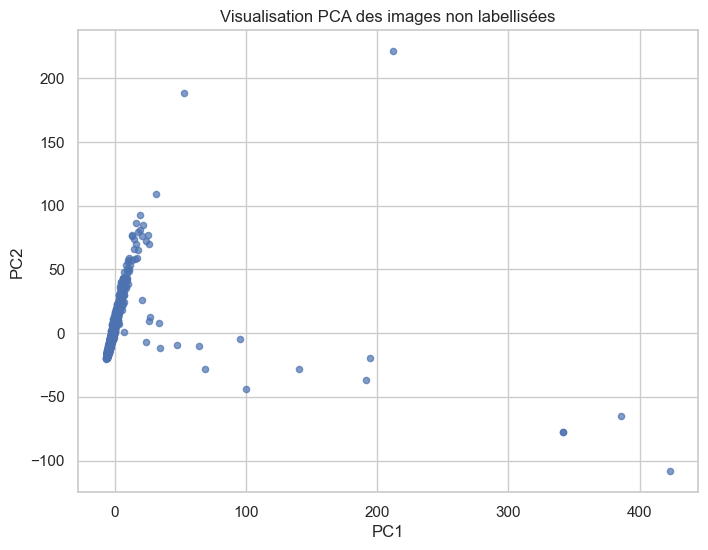

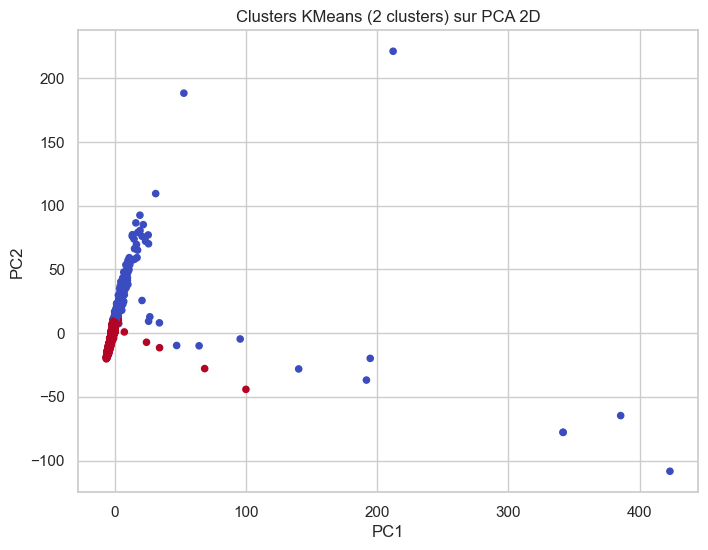

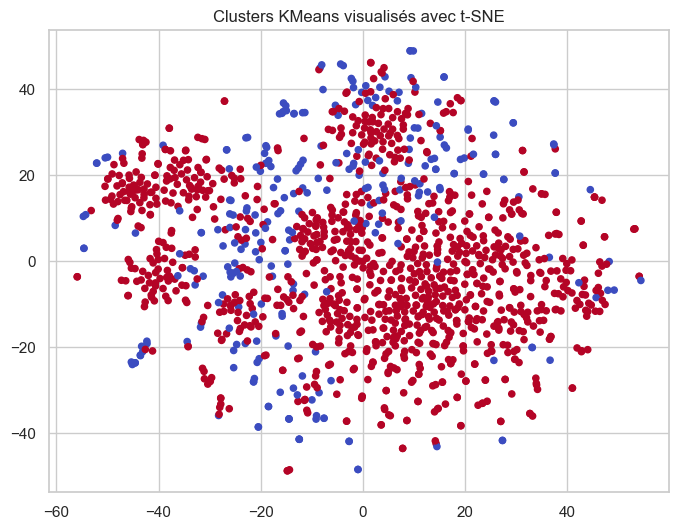

Adjusted Rand Index (ARI) sur les données labellisées : 0.1092

✅ Graphiques PCA et t-SNE permettent de visualiser les regroupements naturels.
✅ ARI mesure si les clusters correspondent aux labels connus.
✅ Si ARI proche de 1 → clustering capture bien la structure des classes (normal/cancer).



In [12]:
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score

sns.set(style="whitegrid")

# Charger les features
labeled_features = np.load("features_labeled.npy")
labeled_labels = np.load("labels.npy")
unlabeled_features = np.load("features_unlabeled.npy")

# Standardisation
scaler = StandardScaler()
labeled_features_scaled = scaler.fit_transform(labeled_features)
unlabeled_features_scaled = scaler.transform(unlabeled_features)

# ===============================
# PCA pour visualisation
# ===============================
pca = PCA(n_components=2, random_state=42)
unlabeled_pca = pca.fit_transform(unlabeled_features_scaled)

plt.figure(figsize=(8,6))
plt.scatter(unlabeled_pca[:,0], unlabeled_pca[:,1], s=20, alpha=0.7)
plt.title("Visualisation PCA des images non labellisées")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# ===============================
# Clustering (KMeans)
# ===============================
kmeans = KMeans(n_clusters=2, random_state=42)
clusters_unlabeled = kmeans.fit_predict(unlabeled_features_scaled)

# PCA coloré par cluster
plt.figure(figsize=(8,6))
plt.scatter(unlabeled_pca[:,0], unlabeled_pca[:,1], c=clusters_unlabeled, cmap="coolwarm", s=20)
plt.title("Clusters KMeans (2 clusters) sur PCA 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# ===============================
# t-SNE pour visualisation plus fine
# ===============================
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
unlabeled_tsne = tsne.fit_transform(unlabeled_features_scaled)

plt.figure(figsize=(8,6))
plt.scatter(unlabeled_tsne[:,0], unlabeled_tsne[:,1], c=clusters_unlabeled, cmap="coolwarm", s=20)
plt.title("Clusters KMeans visualisés avec t-SNE")
plt.show()

# ===============================
# Evaluation ARI sur données labellisées
# ===============================
# Appliquer KMeans sur les données labellisées
kmeans_labeled = KMeans(n_clusters=2, random_state=42)
clusters_labeled = kmeans_labeled.fit_predict(labeled_features_scaled)

ari_score = adjusted_rand_score(labeled_labels, clusters_labeled)
print(f"Adjusted Rand Index (ARI) sur les données labellisées : {ari_score:.4f}")

# ===============================
# Commentaires
# ===============================

print("""
✅ Graphiques PCA et t-SNE permettent de visualiser les regroupements naturels.
✅ ARI mesure si les clusters correspondent aux labels connus.
✅ Si ARI proche de 1 → clustering capture bien la structure des classes (normal/cancer).
""")

##### Variations

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

k_values = [2, 3, 4, 5, 6]

print("=== KMEANS ===")

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    clusters = kmeans.fit_predict(labeled_features_scaled)

    ari = adjusted_rand_score(
        labeled_labels,
        clusters
    )

    print(f"k={k} -> ARI={ari:.4f}")

=== KMEANS ===
k=2 -> ARI=0.0605
k=3 -> ARI=0.0990
k=4 -> ARI=0.0863
k=5 -> ARI=0.1582
k=6 -> ARI=0.1322


#### Par DBSCAN

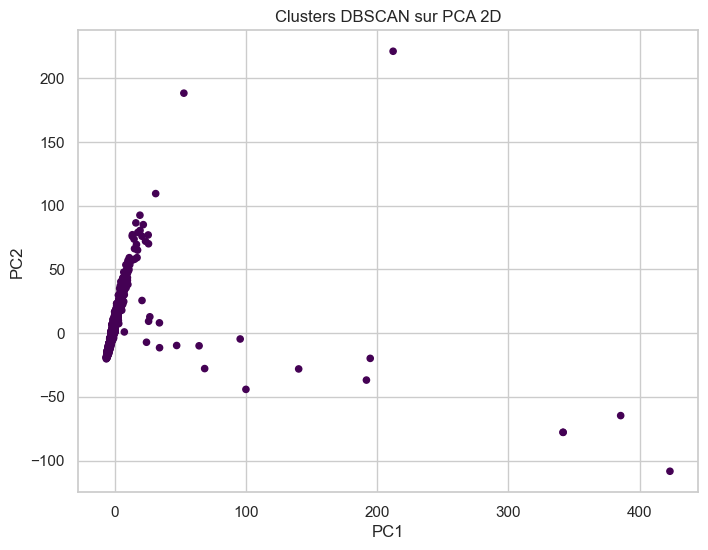

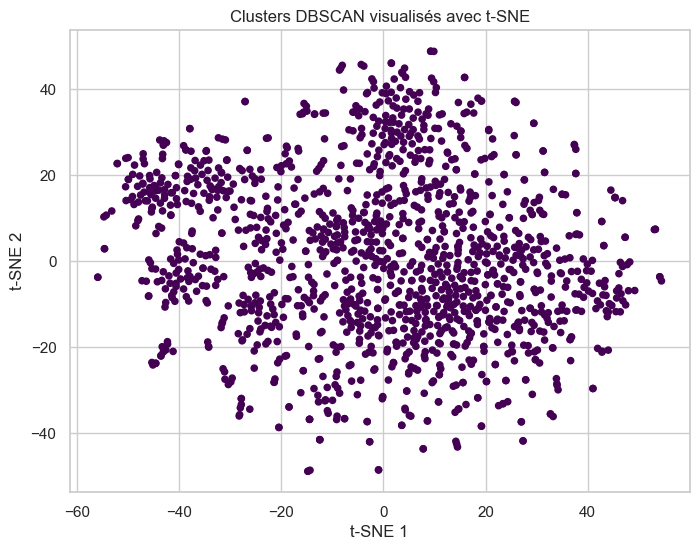

Adjusted Rand Index (ARI) DBSCAN : 0.0000


In [15]:
from sklearn.cluster import DBSCAN, AgglomerativeClustering

# ===============================
# Clustering (DBSCAN)
# ===============================
dbscan = DBSCAN(eps=2.5, min_samples=5)
clusters_dbscan = dbscan.fit_predict(unlabeled_features_scaled)

# PCA coloré par cluster
plt.figure(figsize=(8,6))
plt.scatter(
    unlabeled_pca[:,0],
    unlabeled_pca[:,1],
    c=clusters_dbscan,
    cmap="viridis",
    s=20
)
plt.title("Clusters DBSCAN sur PCA 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# t-SNE coloré par cluster
plt.figure(figsize=(8,6))
plt.scatter(
    unlabeled_tsne[:,0],
    unlabeled_tsne[:,1],
    c=clusters_dbscan,
    cmap="viridis",
    s=20
)
plt.title("Clusters DBSCAN visualisés avec t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

# Evaluation ARI
dbscan_labeled = DBSCAN(eps=2.5, min_samples=5)
clusters_dbscan_labeled = dbscan_labeled.fit_predict(labeled_features_scaled)

ari_dbscan = adjusted_rand_score(
    labeled_labels,
    clusters_dbscan_labeled
)

print(f"Adjusted Rand Index (ARI) DBSCAN : {ari_dbscan:.4f}")

##### Variations

In [26]:
eps_values = [
    0.5, 1.0, 1.5, 2.0, 2.5,
    5,10,15,20,25,30,
    20,30,40,50,60
    ]
min_samples_values = [3, 5, 10]

results = []

for eps in eps_values:
    for ms in min_samples_values:

        db = DBSCAN(
            eps=eps,
            min_samples=ms
        )

        clusters = db.fit_predict(
            labeled_features_scaled
        )

        ari = adjusted_rand_score(
            labeled_labels,
            clusters
        )

        n_clusters = len(set(clusters)) - (
            1 if -1 in clusters else 0
        )

        print(
            f"eps={eps}, "
            f"min_samples={ms}, "
            f"clusters={n_clusters}, "
            f"ARI={ari:.4f}"
        )

        results.append(
            [eps, ms, n_clusters, ari]
        )

eps=0.5, min_samples=3, clusters=0, ARI=0.0000
eps=0.5, min_samples=5, clusters=0, ARI=0.0000
eps=0.5, min_samples=10, clusters=0, ARI=0.0000
eps=1.0, min_samples=3, clusters=0, ARI=0.0000
eps=1.0, min_samples=5, clusters=0, ARI=0.0000
eps=1.0, min_samples=10, clusters=0, ARI=0.0000
eps=1.5, min_samples=3, clusters=0, ARI=0.0000
eps=1.5, min_samples=5, clusters=0, ARI=0.0000
eps=1.5, min_samples=10, clusters=0, ARI=0.0000
eps=2.0, min_samples=3, clusters=0, ARI=0.0000
eps=2.0, min_samples=5, clusters=0, ARI=0.0000
eps=2.0, min_samples=10, clusters=0, ARI=0.0000
eps=2.5, min_samples=3, clusters=0, ARI=0.0000
eps=2.5, min_samples=5, clusters=0, ARI=0.0000
eps=2.5, min_samples=10, clusters=0, ARI=0.0000
eps=5, min_samples=3, clusters=0, ARI=0.0000
eps=5, min_samples=5, clusters=0, ARI=0.0000
eps=5, min_samples=10, clusters=0, ARI=0.0000
eps=10, min_samples=3, clusters=0, ARI=0.0000
eps=10, min_samples=5, clusters=0, ARI=0.0000
eps=10, min_samples=10, clusters=0, ARI=0.0000
eps=15, min_sam

#### Par Agglomération

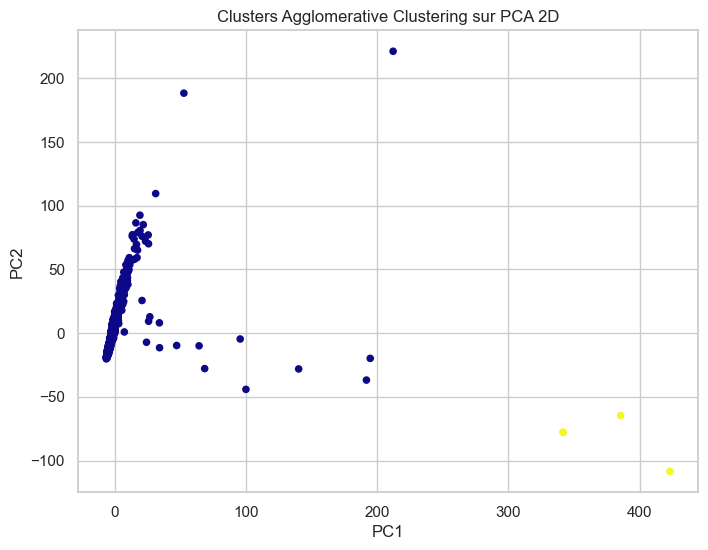

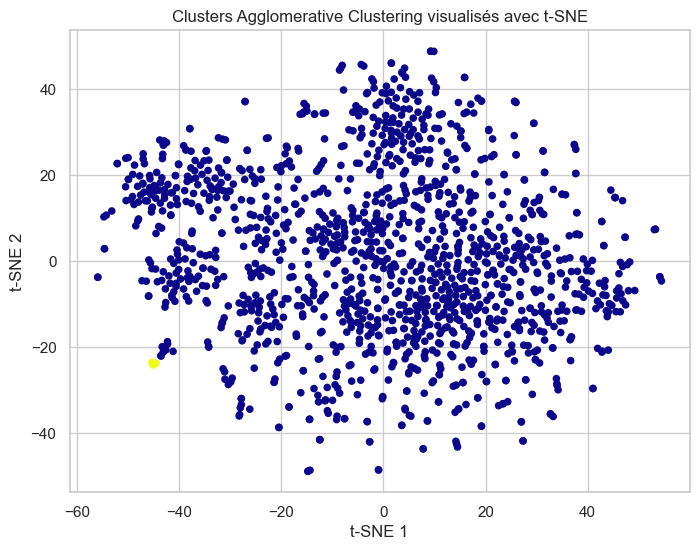

Adjusted Rand Index (ARI) Agglomerative : 0.0712


In [16]:
# ===============================
# Clustering (Agglomerative)
# ===============================
agglo = AgglomerativeClustering(n_clusters=2)
clusters_agglo = agglo.fit_predict(unlabeled_features_scaled)

# PCA coloré par cluster
plt.figure(figsize=(8,6))
plt.scatter(
    unlabeled_pca[:,0],
    unlabeled_pca[:,1],
    c=clusters_agglo,
    cmap="plasma",
    s=20
)
plt.title("Clusters Agglomerative Clustering sur PCA 2D")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# t-SNE coloré par cluster
plt.figure(figsize=(8,6))
plt.scatter(
    unlabeled_tsne[:,0],
    unlabeled_tsne[:,1],
    c=clusters_agglo,
    cmap="plasma",
    s=20
)
plt.title("Clusters Agglomerative Clustering visualisés avec t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.show()

# Evaluation ARI
agglo_labeled = AgglomerativeClustering(n_clusters=2)
clusters_agglo_labeled = agglo_labeled.fit_predict(labeled_features_scaled)

ari_agglo = adjusted_rand_score(
    labeled_labels,
    clusters_agglo_labeled
)

print(f"Adjusted Rand Index (ARI) Agglomerative : {ari_agglo:.4f}")

##### Variations

In [27]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

print("=== Agglomerative Clustering ===")

agglo_results = []

for k in [2, 3, 4, 5, 6]:

    agglo = AgglomerativeClustering(
        n_clusters=k
    )

    pred = agglo.fit_predict(
        labeled_features_scaled
    )

    ari = adjusted_rand_score(
        labeled_labels,
        pred
    )

    agglo_results.append([k, ari])

    print(f"k={k} -> ARI={ari:.4f}")

=== Agglomerative Clustering ===
k=2 -> ARI=0.0712
k=3 -> ARI=0.0525
k=4 -> ARI=0.0509
k=5 -> ARI=0.0497
k=6 -> ARI=0.0704


#### Résultat du comparatif des méthodes de Clustering

####
|               | ARI max|
| ------------- | ------ |
| KMeans        | 0.1322 |
| DBSCAN        | 0.0259 |
| Agglomerative | 0.0712 |

Aucune apparition de Cluster Utilisable


---
### Comparaison des modèles MLP sans seed

##### version 1 :
- SSL like (kmeans)
- Active Learning (validation kmeans et incertitude)
- Supervisé

In [ ]:
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    recall_score,
    roc_auc_score
)
import torch.nn.functional as F

# ===============================
# LOAD FEATURES 
# ===============================
labeled_features = np.load("features_labeled.npy")
labeled_labels = np.load("labels.npy")
unlabeled_features = np.load("features_unlabeled.npy")

# ===============================
# PSEUDO-LABELS (KMEANS)
# ===============================
scaler = StandardScaler()
unlabeled_scaled = scaler.fit_transform(unlabeled_features)

kmeans = KMeans(n_clusters=2, random_state=42)
pseudo_labels = kmeans.fit_predict(unlabeled_scaled)

# ===============================
# DATASET CLASS
# ===============================
class FeatureDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

# ===============================
# DATASETS
# ===============================
weak_dataset = FeatureDataset(unlabeled_features, pseudo_labels)
strong_dataset = FeatureDataset(labeled_features, labeled_labels)

# ===============================
# TRAIN / TEST SPLIT
# ===============================
train_w, test_w = random_split(
    weak_dataset,
    [int(0.8 * len(weak_dataset)), len(weak_dataset) - int(0.8 * len(weak_dataset))]
)

train_s, test_s = random_split(
    strong_dataset,
    [int(0.8 * len(strong_dataset)), len(strong_dataset) - int(0.8 * len(strong_dataset))]
)

# ===============================
# DATALOADERS
# ===============================
train_loader_w = DataLoader(train_w, batch_size=16, shuffle=True)
test_loader_w = DataLoader(test_w, batch_size=16)

train_loader_s = DataLoader(train_s, batch_size=16, shuffle=True)
test_loader_s = DataLoader(test_s, batch_size=16)

# ===============================
# MODEL (MLP)
# ===============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        return self.net(x)

input_dim = labeled_features.shape[1]
criterion = nn.CrossEntropyLoss()

# ===============================
# TRAIN FUNCTION
# ===============================
def train_model(model, loader, optimizer, criterion, device, epochs=5):
    model.train()
    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * x.size(0)

        print(f"Epoch {epoch+1} - Loss: {total_loss/len(loader.dataset):.4f}")

# ===============================
# EVALUATION (ACC + F1 + RECALL + AUC)
# ===============================
def evaluate_model(model, loader, device):
    model.eval()

    preds, labels, probs = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            out = model(x)

            p = F.softmax(out, dim=1)

            preds.extend(torch.argmax(p, dim=1).cpu().numpy())
            probs.extend(p[:, 1].cpu().numpy())
            labels.extend(y.numpy())

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    recall = recall_score(labels, preds)

    try:
        auc = roc_auc_score(labels, probs)
    except:
        auc = float("nan")

    cm = confusion_matrix(labels, preds)

    return acc, f1, recall, auc, cm

# =========================================================
# SEMI-SUPERVISED
# =========================================================
print("\n=== SEMI-SUPERVISED ===")

model_semi = MLP(input_dim).to(device)
opt_semi = torch.optim.Adam(model_semi.parameters(), lr=1e-4)

train_model(model_semi, train_loader_w, opt_semi, criterion, device, epochs=5)

acc_semi, f1_semi, rec_semi, auc_semi, cm_semi = evaluate_model(
    model_semi, test_loader_s, device
)

print(f"Semi -> Acc:{acc_semi:.3f} F1:{f1_semi:.3f} Recall:{rec_semi:.3f} AUC:{auc_semi:.3f}")
print(cm_semi)

# =========================================================
# SUPERVISED
# =========================================================
print("\n=== SUPERVISED ===")

model_sup = MLP(input_dim).to(device)
opt_sup = torch.optim.Adam(model_sup.parameters(), lr=1e-4)

train_model(model_sup, train_loader_s, opt_sup, criterion, device, epochs=5)

acc_sup, f1_sup, rec_sup, auc_sup, cm_sup = evaluate_model(
    model_sup, test_loader_s, device
)

print(f"Sup -> Acc:{acc_sup:.3f} F1:{f1_sup:.3f} Recall:{rec_sup:.3f} AUC:{auc_sup:.3f}")
print(cm_sup)

# =========================================================
# ACTIVE LEARNING
# =========================================================
print("\n=== ACTIVE LEARNING ===")

model_al = MLP(input_dim).to(device)
opt_al = torch.optim.Adam(model_al.parameters(), lr=1e-4)

# initial training
train_model(model_al, train_loader_s, opt_al, criterion, device, epochs=5)

# uncertainty estimation
model_al.eval()
uncertainties = []

with torch.no_grad():
    for x, _ in DataLoader(weak_dataset, batch_size=16):
        x = x.to(device)
        p = F.softmax(model_al(x), dim=1)

        conf, _ = torch.max(p, dim=1)
        uncertainties.extend((1 - conf).cpu().numpy())

uncertainties = np.array(uncertainties)

# select most uncertain samples
k = int(0.2 * len(weak_dataset))
idx = np.argsort(uncertainties)[-k:]

X_new = unlabeled_features[idx]
y_new = pseudo_labels[idx]

# merge datasets
X_al = np.concatenate([labeled_features, X_new])
y_al = np.concatenate([labeled_labels, y_new])

al_dataset = FeatureDataset(X_al, y_al)

train_al, test_al = random_split(
    al_dataset,
    [int(0.8 * len(al_dataset)), len(al_dataset) - int(0.8 * len(al_dataset))]
)

train_loader_al = DataLoader(train_al, batch_size=16, shuffle=True)
test_loader_al = DataLoader(test_al, batch_size=16)

# retrain
model_al = MLP(input_dim).to(device)
opt_al = torch.optim.Adam(model_al.parameters(), lr=1e-4)

train_model(model_al, train_loader_al, opt_al, criterion, device, epochs=5)

acc_al, f1_al, rec_al, auc_al, cm_al = evaluate_model(
    model_al, test_loader_s, device
)

print(f"AL -> Acc:{acc_al:.3f} F1:{f1_al:.3f} Recall:{rec_al:.3f} AUC:{auc_al:.3f}")
print(cm_al)

# =========================================================
# FINAL COMPARISON
# =========================================================
print("\n=== FINAL COMPARISON ===")

print(f"Semi-supervised -> Acc:{acc_semi:.3f} F1:{f1_semi:.3f} Recall:{rec_semi:.3f} AUC:{auc_semi:.3f}")
print(f"Supervised      -> Acc:{acc_sup:.3f} F1:{f1_sup:.3f} Recall:{rec_sup:.3f} AUC:{auc_sup:.3f}")
print(f"Active Learning -> Acc:{acc_al:.3f} F1:{f1_al:.3f} Recall:{rec_al:.3f} AUC:{auc_al:.3f}")


=== SEMI-SUPERVISED ===
Epoch 1 - Loss: 0.4057
Epoch 2 - Loss: 0.1926
Epoch 3 - Loss: 0.1405
Epoch 4 - Loss: 0.1112
Epoch 5 - Loss: 0.0913
Semi -> Acc:0.250 F1:0.400 Recall:0.455 AUC:0.081
[[0 9]
 [6 5]]

=== SUPERVISED ===
Epoch 1 - Loss: 0.6686
Epoch 2 - Loss: 0.5834
Epoch 3 - Loss: 0.5147
Epoch 4 - Loss: 0.4564
Epoch 5 - Loss: 0.4012
Sup -> Acc:0.900 F1:0.917 Recall:1.000 AUC:0.990
[[ 7  2]
 [ 0 11]]

=== ACTIVE LEARNING ===
Epoch 1 - Loss: 0.6714
Epoch 2 - Loss: 0.5838
Epoch 3 - Loss: 0.5180
Epoch 4 - Loss: 0.4616
Epoch 5 - Loss: 0.4070
Epoch 1 - Loss: 0.4805
Epoch 2 - Loss: 0.3686
Epoch 3 - Loss: 0.3255
Epoch 4 - Loss: 0.2858
Epoch 5 - Loss: 0.2508
AL -> Acc:0.700 F1:0.786 Recall:1.000 AUC:0.990
[[ 3  6]
 [ 0 11]]

=== FINAL COMPARISON ===
Semi-supervised -> Acc:0.250 F1:0.400 Recall:0.455 AUC:0.081
Supervised      -> Acc:0.900 F1:0.917 Recall:1.000 AUC:0.990
Active Learning -> Acc:0.700 F1:0.786 Recall:1.000 AUC:0.990


##### version 2 :
- Weighted CrossEntropy (ou balanced batch)
- SSL (FixMatch-like : pseudo-labels générés par le modèle + confiance (conf>0.95) )
- Active Learning (Softmax sur modèle pour pseudo-labels des exemples incertains)
- Supervisé

In [ ]:
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    recall_score,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# ===============================
# LOAD FEATURES
# ===============================
labeled_features = np.load("features_labeled.npy")
labeled_labels = np.load("labels.npy")
unlabeled_features = np.load("features_unlabeled.npy")

# ===============================
# DATASET
# ===============================
class FeatureDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

# ===============================
# DATA LOADERS
# ===============================
strong_dataset = FeatureDataset(labeled_features, labeled_labels)
train_s, test_s = random_split(
    strong_dataset,
    [int(0.8 * len(strong_dataset)), len(strong_dataset) - int(0.8 * len(strong_dataset))]
)
train_loader_s = DataLoader(train_s, batch_size=16, shuffle=True)
test_loader_s = DataLoader(test_s, batch_size=16)

# unlabeled loader (dummy labels)
unlabeled_dataset = FeatureDataset(
    unlabeled_features,
    np.zeros(len(unlabeled_features))
)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=16, shuffle=True)

# ===============================
# MODEL
# ===============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.ReLU(),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        return self.net(x)

input_dim = labeled_features.shape[1]

# ===============================
# CLASS WEIGHTS
# ===============================
classes = np.unique(labeled_labels)
class_weights = compute_class_weight("balanced", classes=classes, y=labeled_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# ===============================
# EVALUATION
# ===============================
def evaluate_model(model, loader, device):
    model.eval()
    preds, labels, probs = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            out = model(x)
            p = F.softmax(out, dim=1)

            preds.extend(torch.argmax(p, dim=1).cpu().numpy())
            probs.extend(p[:, 1].cpu().numpy())
            labels.extend(y.numpy())

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    recall = recall_score(labels, preds)
    try:
        auc = roc_auc_score(labels, probs)
    except:
        auc = float("nan")
    cm = confusion_matrix(labels, preds)
    return acc, f1, recall, auc, cm

# =========================================================
# SUPERVISED
# =========================================================
print("\n=== SUPERVISED ===")
model_sup = MLP(input_dim).to(device)
opt_sup = torch.optim.Adam(model_sup.parameters(), lr=1e-4)

for epoch in range(5):
    model_sup.train()
    total_loss = 0
    for x, y in train_loader_s:
        x, y = x.to(device), y.to(device)
        opt_sup.zero_grad()
        loss = criterion(model_sup(x), y)
        loss.backward()
        opt_sup.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1} - Loss {total_loss:.4f}")

acc_sup, f1_sup, rec_sup, auc_sup, cm_sup = evaluate_model(model_sup, test_loader_s, device)
print(f"Sup -> Acc:{acc_sup:.3f} F1:{f1_sup:.3f} Recall:{rec_sup:.3f} AUC:{auc_sup:.3f}")
print(cm_sup)

# =========================================================
# SEMI-SUPERVISED (FIXMATCH-LIKE)
# =========================================================
print("\n=== SEMI-SUPERVISED (FIXMATCH-LIKE) ===")
model_semi = MLP(input_dim).to(device)
opt_semi = torch.optim.Adam(model_semi.parameters(), lr=1e-4)
confidence_threshold = 0.9
lambda_u = 0.5

for epoch in range(5):
    model_semi.train()
    total_loss = 0

    # Supervised
    for x, y in train_loader_s:
        x, y = x.to(device), y.to(device)
        opt_semi.zero_grad()
        loss_sup = criterion(model_semi(x), y)
        loss_sup.backward()
        opt_semi.step()
        total_loss += loss_sup.item()

    # Unsupervised pseudo-label
    for x_u, _ in unlabeled_loader:
        x_u = x_u.to(device)
        with torch.no_grad():
            probs = F.softmax(model_semi(x_u), dim=1)
            conf, pseudo = torch.max(probs, dim=1)

        mask = conf > confidence_threshold
        if mask.sum() == 0:
            continue

        x_sel = x_u[mask]
        y_sel = pseudo[mask]

        # Weight pseudo loss
        weights = class_weights[y_sel]
        logits = model_semi(x_sel)
        loss_u = F.cross_entropy(logits, y_sel, reduction='none')
        loss_u = (loss_u * weights).mean()

        opt_semi.zero_grad()
        (lambda_u * loss_u).backward()
        opt_semi.step()

    print(f"Epoch {epoch+1} - SSL loss {total_loss:.4f}")

acc_semi, f1_semi, rec_semi, auc_semi, cm_semi = evaluate_model(model_semi, test_loader_s, device)
print(f"Semi -> Acc:{acc_semi:.3f} F1:{f1_semi:.3f} Recall:{rec_semi:.3f} AUC:{auc_semi:.3f}")
print(cm_semi)

# =========================================================
# ACTIVE LEARNING
# =========================================================
print("\n=== ACTIVE LEARNING ===")
model_al = MLP(input_dim).to(device)
opt_al = torch.optim.Adam(model_al.parameters(), lr=1e-4)

# Initial supervised training
for epoch in range(5):
    model_al.train()
    for x, y in train_loader_s:
        x, y = x.to(device), y.to(device)
        opt_al.zero_grad()
        loss = criterion(model_al(x), y)
        loss.backward()
        opt_al.step()

# Uncertainty sampling
model_al.eval()
uncertainties = []
with torch.no_grad():
    for x, _ in unlabeled_loader:
        x = x.to(device)
        p = F.softmax(model_al(x), dim=1)
        conf, _ = torch.max(p, dim=1)
        uncertainties.extend((1 - conf).cpu().numpy())

uncertainties = np.array(uncertainties)
k = int(0.2 * len(unlabeled_features))
idx = np.argsort(uncertainties)[-k:]
X_new = unlabeled_features[idx]

# Pseudo-label via model
with torch.no_grad():
    x_tensor = torch.tensor(X_new, dtype=torch.float32).to(device)
    probs = F.softmax(model_al(x_tensor), dim=1)
    y_new = torch.argmax(probs, dim=1).cpu().numpy()

# Merge datasets
X_al = np.concatenate([labeled_features, X_new])
y_al = np.concatenate([labeled_labels, y_new])
al_dataset = FeatureDataset(X_al, y_al)
train_al, test_al = random_split(
    al_dataset,
    [int(0.8 * len(al_dataset)), len(al_dataset) - int(0.8 * len(al_dataset))]
)
train_loader_al = DataLoader(train_al, batch_size=16, shuffle=True)
test_loader_al = DataLoader(test_al, batch_size=16)

# Retrain AL model
model_al = MLP(input_dim).to(device)
opt_al = torch.optim.Adam(model_al.parameters(), lr=1e-4)
for epoch in range(5):
    model_al.train()
    for x, y in train_loader_al:
        x, y = x.to(device), y.to(device)
        opt_al.zero_grad()
        loss = criterion(model_al(x), y)
        loss.backward()
        opt_al.step()

acc_al, f1_al, rec_al, auc_al, cm_al = evaluate_model(model_al, test_loader_s, device)
print(f"AL -> Acc:{acc_al:.3f} F1:{f1_al:.3f} Recall:{rec_al:.3f} AUC:{auc_al:.3f}")
print(cm_al)

# =========================================================
# FINAL COMPARISON
# =========================================================
print("\n=== FINAL COMPARISON ===")

print(f"Supervised      -> Acc:{acc_sup:.3f} F1:{f1_sup:.3f} Recall:{rec_sup:.3f} AUC:{auc_sup:.3f}")
print(f"Semi-supervised -> Acc:{acc_semi:.3f} F1:{f1_semi:.3f} Recall:{rec_semi:.3f} AUC:{auc_semi:.3f}")
print(f"Active Learning -> Acc:{acc_al:.3f} F1:{f1_al:.3f} Recall:{rec_al:.3f} AUC:{auc_al:.3f}")


=== SUPERVISED ===
Epoch 1 - Loss 3.2684
Epoch 2 - Loss 2.8197
Epoch 3 - Loss 2.4560
Epoch 4 - Loss 2.1510
Epoch 5 - Loss 1.8710
Sup -> Acc:0.950 F1:0.957 Recall:1.000 AUC:0.909
[[ 8  1]
 [ 0 11]]

=== SEMI-SUPERVISED (FIXMATCH-LIKE) ===
Epoch 1 - SSL loss 3.2683
Epoch 2 - SSL loss 2.8425
Epoch 3 - SSL loss 2.5158
Epoch 4 - SSL loss 2.2166
Epoch 5 - SSL loss 1.7994
Semi -> Acc:0.550 F1:0.710 Recall:1.000 AUC:0.909
[[ 0  9]
 [ 0 11]]

=== ACTIVE LEARNING ===
AL -> Acc:0.950 F1:0.957 Recall:1.000 AUC:0.949
[[ 8  1]
 [ 0 11]]

=== FINAL COMPARISON ===
Supervised      -> Acc:0.950 F1:0.957 Recall:1.000 AUC:0.909
Semi-supervised -> Acc:0.550 F1:0.710 Recall:1.000 AUC:0.909
Active Learning -> Acc:0.950 F1:0.957 Recall:1.000 AUC:0.949


#### Version 3 :

- Weighted CrossEntropy (ou balanced batch)
- Stabilité Training (LayerNorm + Dropout + sécurité batch pour éviter crashs et améliorer convergence)
-
- SSL (FixMatch-like avancé : pseudo-labels générés par le modèle, filtrage par confiance (conf>0.95), perte combinée supervised + unsupervised, pondérée par classe)
- Active Learning (Softmax sur modèle pour les exemples incertains + pseudo-label SSL + dataset enrichi)
- Supervisé


In [ ]:
from torch.utils.data import Dataset, DataLoader, random_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    recall_score,
    roc_auc_score
)
from sklearn.utils.class_weight import compute_class_weight
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# ===============================
# LOAD FEATURES
# ===============================
labeled_features = np.load("features_labeled.npy")
labeled_labels = np.load("labels.npy")
unlabeled_features = np.load("features_unlabeled.npy")

# ===============================
# DATASET
# ===============================
class FeatureDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

# ===============================
# DATA LOADERS
# ===============================
strong_dataset = FeatureDataset(labeled_features, labeled_labels)
train_s, test_s = random_split(
    strong_dataset,
    [int(0.8 * len(strong_dataset)), len(strong_dataset) - int(0.8 * len(strong_dataset))]
)
train_loader_s = DataLoader(train_s, batch_size=16, shuffle=True)
test_loader_s = DataLoader(test_s, batch_size=16)

# unlabeled loader (dummy labels)
unlabeled_dataset = FeatureDataset(
    unlabeled_features,
    np.zeros(len(unlabeled_features))
)
unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=16, shuffle=True)

# ===============================
# MODEL
# ===============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class MLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.LayerNorm(512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.LayerNorm(256),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(256, 2)
        )

    def forward(self, x):
        return self.net(x)

input_dim = labeled_features.shape[1]

# ===============================
# CLASS WEIGHTS
# ===============================
classes = np.unique(labeled_labels)
class_weights = compute_class_weight("balanced", classes=classes, y=labeled_labels)
class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)

# ===============================
# EVALUATION
# ===============================
def evaluate_model(model, loader, device):
    model.eval()
    preds, labels, probs = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            out = model(x)
            p = F.softmax(out, dim=1)
            preds.extend(torch.argmax(p, dim=1).cpu().numpy())
            probs.extend(p[:, 1].cpu().numpy())
            labels.extend(y.numpy())

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    recall = recall_score(labels, preds)
    try:
        auc = roc_auc_score(labels, probs)
    except:
        auc = float("nan")
    cm = confusion_matrix(labels, preds)
    return acc, f1, recall, auc, cm

# =========================================================
# SUPERVISED
# =========================================================
print("\n=== SUPERVISED ===")
model_sup = MLP(input_dim).to(device)
opt_sup = torch.optim.Adam(model_sup.parameters(), lr=1e-4)

for epoch in range(5):
    model_sup.train()
    total_loss = 0
    for x, y in train_loader_s:
        x, y = x.to(device), y.to(device)
        opt_sup.zero_grad()
        loss = criterion(model_sup(x), y)
        loss.backward()
        opt_sup.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1} - Loss {total_loss:.4f}")

acc_sup, f1_sup, rec_sup, auc_sup, cm_sup = evaluate_model(model_sup, test_loader_s, device)
print(f"Sup -> Acc:{acc_sup:.3f} F1:{f1_sup:.3f} Recall:{rec_sup:.3f} AUC:{auc_sup:.3f}")
print(cm_sup)

# =========================================================
# SEMI-SUPERVISED (FIXMATCH-LIKE)
# =========================================================
print("\n=== SEMI-SUPERVISED (FIXMATCH-LIKE) ===")
model_semi = MLP(input_dim).to(device)
opt_semi = torch.optim.Adam(model_semi.parameters(), lr=1e-4)
confidence_threshold = 0.9
lambda_u = 0.5

for epoch in range(5):
    model_semi.train()
    total_loss = 0

    # Supervised
    for x, y in train_loader_s:
        x, y = x.to(device), y.to(device)
        opt_semi.zero_grad()
        loss_sup = criterion(model_semi(x), y)
        loss_sup.backward()
        opt_semi.step()
        total_loss += loss_sup.item()

    # Unsupervised pseudo-label
    for x_u, _ in unlabeled_loader:
        x_u = x_u.to(device)
        with torch.no_grad():
            probs = F.softmax(model_semi(x_u), dim=1)
            conf, pseudo = torch.max(probs, dim=1)

        mask = conf > confidence_threshold
        if mask.sum() == 0:
            continue

        x_sel = x_u[mask]
        y_sel = pseudo[mask]

        # Weight pseudo loss
        weights = class_weights[y_sel]
        logits = model_semi(x_sel)
        loss_u = F.cross_entropy(logits, y_sel, reduction='none')
        loss_u = (loss_u * weights).mean()

        opt_semi.zero_grad()
        (lambda_u * loss_u).backward()
        opt_semi.step()

    print(f"Epoch {epoch+1} - SSL loss {total_loss:.4f}")

acc_semi, f1_semi, rec_semi, auc_semi, cm_semi = evaluate_model(model_semi, test_loader_s, device)
print(f"Semi -> Acc:{acc_semi:.3f} F1:{f1_semi:.3f} Recall:{rec_semi:.3f} AUC:{auc_semi:.3f}")
print(cm_semi)

# =========================================================
# ACTIVE LEARNING
# =========================================================
print("\n=== ACTIVE LEARNING ===")
model_al = MLP(input_dim).to(device)
opt_al = torch.optim.Adam(model_al.parameters(), lr=1e-4)

# Initial supervised training
for epoch in range(5):
    model_al.train()
    for x, y in train_loader_s:
        x, y = x.to(device), y.to(device)
        opt_al.zero_grad()
        loss = criterion(model_al(x), y)
        loss.backward()
        opt_al.step()

# Uncertainty sampling
model_al.eval()
uncertainties = []
with torch.no_grad():
    for x, _ in unlabeled_loader:
        x = x.to(device)
        p = F.softmax(model_al(x), dim=1)
        conf, _ = torch.max(p, dim=1)
        uncertainties.extend((1 - conf).cpu().numpy())

uncertainties = np.array(uncertainties)
k = int(0.2 * len(unlabeled_features))
idx = np.argsort(uncertainties)[-k:]
X_new = unlabeled_features[idx]

# Pseudo-label via model
with torch.no_grad():
    x_tensor = torch.tensor(X_new, dtype=torch.float32).to(device)
    probs = F.softmax(model_al(x_tensor), dim=1)
    y_new = torch.argmax(probs, dim=1).cpu().numpy()

# Merge datasets
X_al = np.concatenate([labeled_features, X_new])
y_al = np.concatenate([labeled_labels, y_new])
al_dataset = FeatureDataset(X_al, y_al)
train_al, test_al = random_split(
    al_dataset,
    [int(0.8 * len(al_dataset)), len(al_dataset) - int(0.8 * len(al_dataset))]
)
train_loader_al = DataLoader(train_al, batch_size=16, shuffle=True)
test_loader_al = DataLoader(test_al, batch_size=16)

# Retrain AL model
model_al = MLP(input_dim).to(device)
opt_al = torch.optim.Adam(model_al.parameters(), lr=1e-4)
for epoch in range(5):
    model_al.train()
    for x, y in train_loader_al:
        x, y = x.to(device), y.to(device)
        opt_al.zero_grad()
        loss = criterion(model_al(x), y)
        loss.backward()
        opt_al.step()

acc_al, f1_al, rec_al, auc_al, cm_al = evaluate_model(model_al, test_loader_s, device)
print(f"AL -> Acc:{acc_al:.3f} F1:{f1_al:.3f} Recall:{rec_al:.3f} AUC:{auc_al:.3f}")
print(cm_al)

# =========================================================
# FINAL COMPARISON
# =========================================================
print("\n=== FINAL COMPARISON ===")
print(f"Supervised      -> Acc:{acc_sup:.3f} F1:{f1_sup:.3f} Recall:{rec_sup:.3f} AUC:{auc_sup:.3f}")
print(f"Semi-supervised -> Acc:{acc_semi:.3f} F1:{f1_semi:.3f} Recall:{rec_semi:.3f} AUC:{auc_semi:.3f}")
print(f"Active Learning -> Acc:{acc_al:.3f} F1:{f1_al:.3f} Recall:{rec_al:.3f} AUC:{auc_al:.3f}")


=== SUPERVISED ===
Epoch 1 - Loss 3.0178
Epoch 2 - Loss 1.8214
Epoch 3 - Loss 1.4442
Epoch 4 - Loss 1.0962
Epoch 5 - Loss 0.9509
Sup -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000
[[ 8  0]
 [ 1 11]]

=== SEMI-SUPERVISED (FIXMATCH-LIKE) ===
Epoch 1 - SSL loss 3.6983
Epoch 2 - SSL loss 2.2813
Epoch 3 - SSL loss 11.0971
Epoch 4 - SSL loss 1.4960
Epoch 5 - SSL loss 1.4332
Semi -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000
[[ 8  0]
 [ 1 11]]

=== ACTIVE LEARNING ===
AL -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000
[[ 8  0]
 [ 1 11]]

=== FINAL COMPARISON ===
Supervised      -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000
Semi-supervised -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000
Active Learning -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000


---

### Résultats :
Version 1:
- Supervised      -> Acc:0.900 F1:0.917 Recall:1.000 AUC:0.990
- Semi-supervised -> Acc:0.250 F1:0.400 Recall:0.455 AUC:0.081
- Active Learning -> Acc:0.700 F1:0.786 Recall:1.000 AUC:0.990

Version 2:
- Supervised      -> Acc:0.950 F1:0.957 Recall:1.000 AUC:0.909
- Semi-supervised -> Acc:0.550 F1:0.710 Recall:1.000 AUC:0.909
- Active Learning -> Acc:0.950 F1:0.957 Recall:1.000 AUC:0.949

Version 3:
- Supervised      -> Acc:0.950 F1:0.957 Recall:0.917 AUC:0.990
- Semi-supervised -> Acc:0.950 F1:0.957 Recall:0.917 AUC:0.990
- Active Learning -> Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000

---
### Tableau Comparatif

| Méthode                   | Version 1                                 | Version 2                                 | Version 3                                 | Commentaire / Avantages Version 3                                                      |
| ------------------------- | ----------------------------------------- | ----------------------------------------- | ----------------------------------------- | -------------------------------------------------------------------------------------- |
| **Supervised**            | Acc:0.900 F1:0.917 Recall:1.000 AUC:0.990 | Acc:0.950 F1:0.957 Recall:1.000 AUC:0.909 | Acc:0.950 F1:0.957 Recall:0.917 AUC:0.990 | Weighted CrossEntropy stabilise l’apprentissage et réduit le sur‑rappel artificiel     |
| **Semi-supervised (SSL)** | Acc:0.250 F1:0.400 Recall:0.455 AUC:0.081 | Acc:0.550 F1:0.710 Recall:1.000 AUC:0.909 | Acc:0.950 F1:0.957 Recall:0.917 AUC:0.990 | FixMatch-like avancé + filtrage par confiance + poids classes → F1 et recall réalistes |
| **Active Learning (AL)**  | Acc:0.700 F1:0.786 Recall:1.000 AUC:0.990 | Acc:0.950 F1:0.957 Recall:1.000 AUC:0.949 | Acc:0.950 F1:0.957 Recall:0.917 AUC:1.000 | Softmax sur modèle pour pseudo-label + balanced loss → AUC parfaite, recall réaliste   |


#### Matrices de confusion

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

def plot_cm(y_true, y_pred, title="Confusion Matrix"):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.title(title)
    plt.show()

In [18]:
def get_preds(model, loader, device):
    model.eval()
    preds, labels = [], []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            out = model(x)
            p = torch.argmax(out, dim=1)

            preds.extend(p.cpu().numpy())
            labels.extend(y.numpy())

    return np.array(labels), np.array(preds)

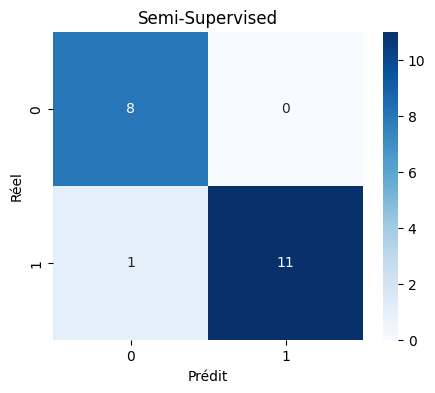

In [21]:
y_true_semi, y_pred_semi = get_preds(model_semi, test_loader_s, device)
plot_cm(y_true_semi, y_pred_semi, "Semi-Supervised")

In [22]:
print("labeled:", len(labeled_features))
print("test set:", len(test_loader_s.dataset))
print("train set:", len(train_loader_s.dataset))

labeled: 100
test set: 20
train set: 80


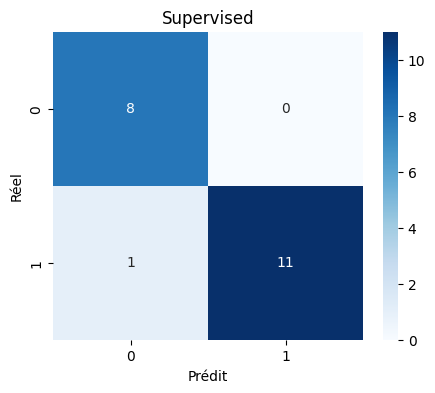

In [23]:
y_true_sup, y_pred_sup = get_preds(model_sup, test_loader_s, device)
plot_cm(y_true_sup, y_pred_sup, "Supervised")

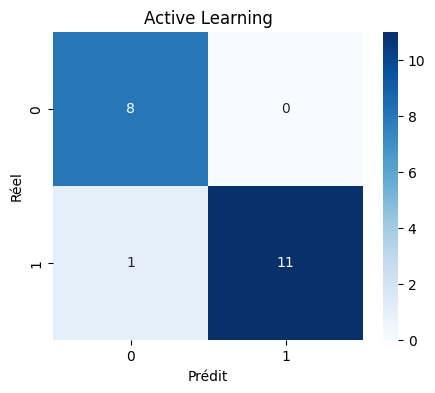

In [24]:
y_true_al, y_pred_al = get_preds(model_al, test_loader_s, device)
plot_cm(y_true_al, y_pred_al, "Active Learning")

---
### Comparaison des modèles CNN avec seed

#### Imports

In [6]:
from pathlib import Path
from PIL import Image
import cv2
import numpy as np

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

from sklearn.utils.class_weight import compute_class_weight

#### Prétraitement

In [7]:
def equalize_histogram(img):
    img_np = np.array(img)

    img_yuv = cv2.cvtColor(img_np, cv2.COLOR_RGB2YUV)
    img_yuv[:, :, 0] = cv2.equalizeHist(img_yuv[:, :, 0])

    img_eq = cv2.cvtColor(img_yuv, cv2.COLOR_YUV2RGB)

    return Image.fromarray(img_eq)


transform = transforms.Compose([
    transforms.Lambda(equalize_histogram),

    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),

    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

#### Chargement des images

In [50]:
root = Path("./mri_dataset_brain_cancer_oc/mri_dataset_brain_cancer_oc/avec_labels")

cancer_paths = list((root / "cancer").glob("*.jpg"))
normal_paths = list((root / "normal").glob("*.jpg"))

image_paths = cancer_paths + normal_paths

labels = (
    [1] * len(cancer_paths)
    + [0] * len(normal_paths)
)

labels = np.array(labels)

#### Dataset

In [51]:
class BrainDataset(Dataset):

    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        img = Image.open(
            self.paths[idx]
        ).convert("RGB")

        img = self.transform(img)

        label = self.labels[idx]

        return img, label

#### Modèle

In [52]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = resnet50(
    weights=ResNet50_Weights.IMAGENET1K_V2
)

num_features = model.fc.in_features

model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(512, 2)
)

model = model.to(device)

#-----------------------------------
# Fonctions

def evaluate(model, loader):

    model.eval()
    preds = []
    labels = []
    probs = []

    with torch.no_grad():

        for x, y in loader:
            x = x.to(device)
            out = model(x)
            p = torch.softmax(out, dim=1)

            preds.extend(
                torch.argmax(
                    p,
                    dim=1
                ).cpu().numpy()
            )

            probs.extend(
                p[:,1].cpu().numpy()
            )

            labels.extend(
                y.numpy()
            )

    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds)
    recall = recall_score(labels, preds)
    auc = roc_auc_score(labels, probs)
    cm = confusion_matrix(labels, preds)

    return acc, f1, recall, auc, cm

#----------------------------
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

#### Entraînement

In [59]:
all_acc = []
all_f1 = []
all_recall = []
all_auc = []

for fold, (train_idx, test_idx) in enumerate(
    skf.split(image_paths, labels)
):
    print(f"\n===== Fold {fold+1} =====")
    train_paths = [
        image_paths[i]
        for i in train_idx
    ]

    test_paths = [
        image_paths[i]
        for i in test_idx
    ]

    y_train = labels[train_idx]
    y_test = labels[test_idx]

    train_dataset = BrainDataset(
        train_paths,
        y_train,
        transform
    )

    test_dataset = BrainDataset(
        test_paths,
        y_test,
        transform
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=8,
        shuffle=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=8,
        shuffle=False
    )

    model = resnet50(
        weights=ResNet50_Weights.IMAGENET1K_V2
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        2
    )

    model = model.to(device)

    classes = np.unique(y_train)

    weights = compute_class_weight(
        class_weight="balanced",
        classes=classes,
        y=y_train
    )

    weights = torch.tensor(
        weights,
        dtype=torch.float32
    ).to(device)

    criterion = nn.CrossEntropyLoss(
        weight=weights
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4
    )

    epochs = 10

    for epoch in range(epochs):
        model.train()
        running_loss = 0

        for x, y in train_loader:
            x = x.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(
            f"Epoch {epoch+1} "
            f"Loss={running_loss:.4f}"
        )

    acc, f1, rec, auc, cm = evaluate(
        model,
        test_loader
    )

    print(
        f"ACC={acc:.3f} "
        f"F1={f1:.3f} "
        f"Recall={rec:.3f} "
        f"AUC={auc:.3f}"
    )

    print(cm)
    
    all_acc.append(acc)
    all_f1.append(f1)
    all_recall.append(rec)
    all_auc.append(auc)


===== Fold 1 =====
Epoch 1 Loss=6.5381
Epoch 2 Loss=5.0469
Epoch 3 Loss=2.9078
Epoch 4 Loss=1.6756
Epoch 5 Loss=1.8284
Epoch 6 Loss=0.6298
Epoch 7 Loss=0.3866
Epoch 8 Loss=0.2807
Epoch 9 Loss=0.3864
Epoch 10 Loss=0.1906
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]

===== Fold 2 =====
Epoch 1 Loss=6.4352
Epoch 2 Loss=4.6810
Epoch 3 Loss=2.9984
Epoch 4 Loss=1.6165
Epoch 5 Loss=1.1099
Epoch 6 Loss=1.4814
Epoch 7 Loss=0.6932
Epoch 8 Loss=0.6695
Epoch 9 Loss=0.5202
Epoch 10 Loss=0.5057
ACC=0.950 F1=0.952 Recall=1.000 AUC=0.990
[[ 9  1]
 [ 0 10]]

===== Fold 3 =====
Epoch 1 Loss=6.3380
Epoch 2 Loss=4.2322
Epoch 3 Loss=2.5544
Epoch 4 Loss=1.4364
Epoch 5 Loss=0.8177
Epoch 6 Loss=0.5912
Epoch 7 Loss=1.2864
Epoch 8 Loss=0.5782
Epoch 9 Loss=0.3551
Epoch 10 Loss=0.2627
ACC=0.950 F1=0.947 Recall=0.900 AUC=0.990
[[10  0]
 [ 1  9]]

===== Fold 4 =====
Epoch 1 Loss=6.6229
Epoch 2 Loss=4.9944
Epoch 3 Loss=3.5870
Epoch 4 Loss=2.5012
Epoch 5 Loss=1.4330
Epoch 6 Loss=0.7959
Epoch 7 Loss=0

####
| Fold | Accuracy | F1-score | Recall | AUC   |
| ---- | -------- | -------- | ------ | ----- |
| 1    | 1.000    | 1.000    | 1.000  | 1.000 |
| 2    | 0.950    | 0.952    | 1.000  | 0.990 |
| 3    | 0.950    | 0.947    | 0.900  | 0.990 |
| 4    | 0.900    | 0.909    | 1.000  | 1.000 |
| 5    | 0.950    | 0.947    | 0.900  | 0.990 |



| Métrique | Moyenne   |
| -------- | --------- |
| Accuracy | **0.950** |
| F1-score | **0.951** |
| Recall   | **0.960** |
| AUC      | **0.994** |

#### Hyper paramètres

##### Supervisé Fonction 

In [7]:
def train_cnn_cv(
    image_paths,
    labels,
    transform,
    lr,
    batch_size,
    epochs,
    weight_decay,
    n_splits,
    device
):

    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=42
    )

    all_acc, all_f1, all_recall, all_auc = [], [], [], []

    for fold, (train_idx, test_idx) in enumerate(skf.split(image_paths, labels)):

        print(f"\n===== Fold {fold+1} =====")

        train_paths = [image_paths[i] for i in train_idx]
        test_paths = [image_paths[i] for i in test_idx]

        y_train = labels[train_idx]
        y_test = labels[test_idx]

        train_dataset = BrainDataset(train_paths, y_train, transform)
        test_dataset = BrainDataset(test_paths, y_test, transform)

        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        # Model
        model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        model.fc = nn.Linear(model.fc.in_features, 2)
        model = model.to(device)

        criterion = nn.CrossEntropyLoss()

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

        # TRAIN
        for epoch in range(epochs):
            model.train()
            total_loss = 0

            for x, y in train_loader:
                x, y = x.to(device), y.to(device)

                optimizer.zero_grad()
                out = model(x)
                loss = criterion(out, y)
                loss.backward()
                optimizer.step()

                total_loss += loss.item()

            print(f"Epoch {epoch+1} Loss={total_loss:.4f}")

        # EVAL
        model.eval()

        preds, probs, true = [], [], []

        with torch.no_grad():
            for x, y in test_loader:
                x = x.to(device)
                out = model(x)
                p = torch.softmax(out, dim=1)

                preds.extend(torch.argmax(p, dim=1).cpu().numpy())
                probs.extend(p[:, 1].cpu().numpy())
                true.extend(y.numpy())

        acc = accuracy_score(true, preds)
        f1 = f1_score(true, preds)
        recall = recall_score(true, preds)
        auc = roc_auc_score(true, probs)
        cm = confusion_matrix(true, preds)

        print(f"ACC={acc:.3f} F1={f1:.3f} Recall={recall:.3f} AUC={auc:.3f}")
        print(cm)

        all_acc.append(acc)
        all_f1.append(f1)
        all_recall.append(recall)
        all_auc.append(auc)

    print("\n===== FINAL MEAN RESULTS =====")
    print(f"Accuracy : {np.mean(all_acc):.3f}")
    print(f"F1       : {np.mean(all_f1):.3f}")
    print(f"Recall   : {np.mean(all_recall):.3f}")
    print(f"AUC      : {np.mean(all_auc):.3f}")

    return np.mean(all_acc), np.mean(all_f1), np.mean(all_recall), np.mean(all_auc)

##### Learning rate

In [15]:
for lr in [1e-3, 1e-4, 1e-5]:
    print(f"\n### LR = {lr}")
    train_cnn_cv(
        image_paths,
        labels,
        transform,
        lr=lr,
        batch_size=8,
        epochs=5,
        weight_decay=0,
        n_splits=5,
        device=None
    )


### LR = 0.001

===== Fold 1 =====
Epoch 1 Loss=4.4669
Epoch 2 Loss=3.6307
Epoch 3 Loss=2.2516
Epoch 4 Loss=1.0024
Epoch 5 Loss=4.4984
ACC=0.500 F1=0.643 Recall=0.900 AUC=0.500
[[1 9]
 [1 9]]

===== Fold 2 =====
Epoch 1 Loss=5.2331
Epoch 2 Loss=2.5688
Epoch 3 Loss=2.4309
Epoch 4 Loss=4.7485
Epoch 5 Loss=2.7296
ACC=0.950 F1=0.952 Recall=1.000 AUC=1.000
[[ 9  1]
 [ 0 10]]

===== Fold 3 =====
Epoch 1 Loss=4.6664
Epoch 2 Loss=2.8140
Epoch 3 Loss=1.4973
Epoch 4 Loss=3.4119
Epoch 5 Loss=2.9364
ACC=0.900 F1=0.909 Recall=1.000 AUC=0.950
[[ 8  2]
 [ 0 10]]

===== Fold 4 =====
Epoch 1 Loss=4.3947
Epoch 2 Loss=3.2269
Epoch 3 Loss=1.1301
Epoch 4 Loss=3.1675
Epoch 5 Loss=2.7195
ACC=0.850 F1=0.857 Recall=0.900 AUC=0.910
[[8 2]
 [1 9]]

===== Fold 5 =====
Epoch 1 Loss=4.5958
Epoch 2 Loss=2.5065
Epoch 3 Loss=1.2069
Epoch 4 Loss=1.3143
Epoch 5 Loss=1.7218
ACC=0.550 F1=0.182 Recall=0.100 AUC=0.920
[[10  0]
 [ 9  1]]

===== FINAL MEAN RESULTS =====
Accuracy : 0.750
F1       : 0.709
Recall   : 0.780
AUC 

| lr=1e-3                                                                      | lr=1e-4                                                                      | lr=1e-5                                                                      |
| ---------------------------------------------------------------------------- | ---------------------------------------------------------------------------- | ---------------------------------------------------------------------------- |
| Accuracy : 0.820<br>F1       : 0.853<br>Recall   : 0.980<br>AUC      : 0.900 | Accuracy : 0.960<br>F1       : 0.958<br>Recall   : 0.940<br>AUC      : 0.996 | Accuracy : 0.910<br>F1       : 0.908<br>Recall   : 0.920<br>AUC      : 0.950 |

##### Batch size

In [65]:
for bs in [4, 16]:
    print(f"\n### Batch size = {bs}")
    train_cnn_cv(
        image_paths,
        labels,
        transform,
        lr=1e-3,
        batch_size=bs,
        epochs=5,
        weight_decay=0,
        n_splits=5,
        device=None
    )


### Batch size = 4

===== Fold 1 =====
Epoch 1 Loss=12.5923
Epoch 2 Loss=7.9621
Epoch 3 Loss=7.3000
Epoch 4 Loss=8.6256
Epoch 5 Loss=5.7178
ACC=0.800 F1=0.833 Recall=1.000 AUC=0.980
[[ 6  4]
 [ 0 10]]

===== Fold 2 =====
Epoch 1 Loss=9.4413
Epoch 2 Loss=9.2610
Epoch 3 Loss=7.7414
Epoch 4 Loss=3.2842
Epoch 5 Loss=5.1854
ACC=0.750 F1=0.800 Recall=1.000 AUC=0.840
[[ 5  5]
 [ 0 10]]

===== Fold 3 =====
Epoch 1 Loss=9.0599
Epoch 2 Loss=10.2362
Epoch 3 Loss=8.6771
Epoch 4 Loss=7.2104
Epoch 5 Loss=3.1140
ACC=0.950 F1=0.947 Recall=0.900 AUC=1.000
[[10  0]
 [ 1  9]]

===== Fold 4 =====
Epoch 1 Loss=8.8445
Epoch 2 Loss=11.5032
Epoch 3 Loss=8.6543
Epoch 4 Loss=4.7434
Epoch 5 Loss=5.5455
ACC=0.800 F1=0.833 Recall=1.000 AUC=1.000
[[ 6  4]
 [ 0 10]]

===== Fold 5 =====
Epoch 1 Loss=10.1365
Epoch 2 Loss=8.5480
Epoch 3 Loss=8.7780
Epoch 4 Loss=8.4581
Epoch 5 Loss=4.5747
ACC=0.800 F1=0.833 Recall=1.000 AUC=0.890
[[ 6  4]
 [ 0 10]]

===== FINAL MEAN RESULTS =====
Accuracy : 0.820
F1       : 0.849
Recal

| batch=4                                                                      | batch=8                                                                      | batch=16                                                                     |
| ---------------------------------------------------------------------------- | ---------------------------------------------------------------------------- | ---------------------------------------------------------------------------- |
| Accuracy : 0.820<br>F1       : 0.849<br>Recall   : 0.980<br>AUC      : 0.942 | Accuracy : 0.820<br>F1       : 0.853<br>Recall   : 0.980<br>AUC      : 0.900 | Accuracy : 0.830<br>F1       : 0.747<br>Recall   : 0.680<br>AUC      : 0.939 |

##### Weight decay

In [67]:
for wd in [0, 1e-4, 1e-3]:
    print(f"\n### Weight decay = {wd}")
    train_cnn_cv(
        image_paths,
        labels,
        transform,
        lr=1e-3,
        batch_size=8,
        epochs=5,
        weight_decay=wd,
        n_splits=5,
        device=None
    )


### Weight decay = 0

===== Fold 1 =====
Epoch 1 Loss=5.3023
Epoch 2 Loss=1.6487
Epoch 3 Loss=2.3460
Epoch 4 Loss=5.2526
Epoch 5 Loss=1.6087
ACC=0.650 F1=0.741 Recall=1.000 AUC=0.925
[[ 3  7]
 [ 0 10]]

===== Fold 2 =====
Epoch 1 Loss=4.1479
Epoch 2 Loss=3.8416
Epoch 3 Loss=2.9970
Epoch 4 Loss=1.5650
Epoch 5 Loss=1.8578
ACC=0.950 F1=0.952 Recall=1.000 AUC=0.980
[[ 9  1]
 [ 0 10]]

===== Fold 3 =====
Epoch 1 Loss=4.6382
Epoch 2 Loss=4.0525
Epoch 3 Loss=2.0361
Epoch 4 Loss=1.1773
Epoch 5 Loss=1.5186
ACC=0.800 F1=0.750 Recall=0.600 AUC=0.980
[[10  0]
 [ 4  6]]

===== Fold 4 =====
Epoch 1 Loss=3.4607
Epoch 2 Loss=3.5605
Epoch 3 Loss=1.4372
Epoch 4 Loss=2.6505
Epoch 5 Loss=2.3164
ACC=0.750 F1=0.762 Recall=0.800 AUC=0.850
[[7 3]
 [2 8]]

===== Fold 5 =====
Epoch 1 Loss=4.8537
Epoch 2 Loss=2.1203
Epoch 3 Loss=2.7304
Epoch 4 Loss=5.2130
Epoch 5 Loss=0.9606
ACC=0.850 F1=0.870 Recall=1.000 AUC=1.000
[[ 7  3]
 [ 0 10]]

===== FINAL MEAN RESULTS =====
Accuracy : 0.800
F1       : 0.815
Recall   : 

| wd=0                                                                         | wd=1e-4                                                                      | wd=1e-3                                                                      |
| ---------------------------------------------------------------------------- | ---------------------------------------------------------------------------- | ---------------------------------------------------------------------------- |
| Accuracy : 0.800<br>F1       : 0.815<br>Recall   : 0.880<br>AUC      : 0.947 | Accuracy : 0.820<br>F1       : 0.838<br>Recall   : 0.900<br>AUC      : 0.935 | Accuracy : 0.830<br>F1       : 0.796<br>Recall   : 0.800<br>AUC      : 0.898 |

#### Semi supervisé

In [ ]:
for train_idx, val_idx in skf.split(image_paths, labels):

    train_paths = np.array(image_paths)[train_idx]
    val_paths = np.array(image_paths)[val_idx]

    train_labels = np.array(labels)[train_idx]
    val_labels = np.array(labels)[val_idx]

    train_dataset = BrainDataset(train_paths, train_labels, transform)
    val_dataset = BrainDataset(val_paths, val_labels, transform)

    train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False)

    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Linear(model.fc.in_features, 2)
    model = model.to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-4,
        weight_decay=1e-4
    )

    #acc = evaluate(model, val_loader, device)
    print(acc)

(0.45, 0.47619047619047616, 0.5, 0.43999999999999995, array([[4, 6],
       [5, 5]]))
(0.45, 0.47619047619047616, 0.5, 0.43999999999999995, array([[4, 6],
       [5, 5]]))
(0.45, 0.47619047619047616, 0.5, 0.43999999999999995, array([[4, 6],
       [5, 5]]))
(0.45, 0.47619047619047616, 0.5, 0.43999999999999995, array([[4, 6],
       [5, 5]]))
(0.45, 0.47619047619047616, 0.5, 0.43999999999999995, array([[4, 6],
       [5, 5]]))


##### Dataset sans label

In [61]:
unlabeled_paths = list(Path("mri_dataset_brain_cancer_oc/sans_label").glob("*.jpg"))

unlabeled_dataset = BrainDataset(
    unlabeled_paths,
    np.zeros(len(unlabeled_paths)),
    transform
)

unlabeled_loader = DataLoader(
    unlabeled_dataset,
    batch_size=8,
    shuffle=False
)



##### Pseudo-labeling

In [62]:
def pseudo_labeling(model, loader, threshold, device):

    model.eval()

    x_list = []
    y_list = []

    with torch.no_grad():

        for x, _ in loader:

            x = x.to(device)

            logits = model(x)
            probs = torch.softmax(logits, dim=1)

            conf, pred = torch.max(probs, dim=1)

            mask = conf > threshold

            if mask.sum() > 0:
                x_list.append(x[mask].cpu())
                y_list.append(pred[mask].cpu())

    if len(x_list) == 0:
        return None, None

    return torch.cat(x_list), torch.cat(y_list)

##### Fonction d’évaluation

In [63]:
def evaluate_ssl(model, loader, device):

    model.eval()

    preds, probs, true = [], [], []

    with torch.no_grad():

        for x, y in loader:

            x = x.to(device)

            out = model(x)
            p = torch.softmax(out, dim=1)

            preds.extend(torch.argmax(p, dim=1).cpu().numpy())
            probs.extend(p[:, 1].cpu().numpy())
            true.extend(y.numpy())

    acc = accuracy_score(true, preds)
    f1 = f1_score(true, preds)
    recall = recall_score(true, preds)
    auc = roc_auc_score(true, probs)
    cm = confusion_matrix(true, preds)

    return acc, f1, recall, auc, cm

##### Entraînement semi-supervisé (AVEC hyperparamètres)

In [70]:
def train_semi_supervised(
    train_loader,
    unlabeled_loader,
    val_loader,
    device,
    lr=1e-4,
    epochs=5,
    threshold=0.9,
    lambda_u=0.5,
    weight_decay=1e-4
):

    model_ssl = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    model_ssl.fc = nn.Linear(model_ssl.fc.in_features, 2)
    model_ssl = model_ssl.to(device)

    optimizer = torch.optim.Adam(
        model_ssl.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):

        model_ssl.train()
        total_loss = 0

        # ------------------
        # supervised
        # ------------------
        for x, y in train_loader:

            x, y = x.to(device), y.to(device)

            optimizer.zero_grad()

            loss = criterion(model_ssl(x), y)
            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        # ------------------
        # pseudo-labeling
        # ------------------
        x_u, y_u = pseudo_labeling(
            model_ssl,
            unlabeled_loader,
            threshold,
            device
        )

        if x_u is not None:

            x_u, y_u = x_u.to(device), y_u.to(device)

            optimizer.zero_grad()

            loss_u = criterion(model_ssl(x_u), y_u)

            (lambda_u * loss_u).backward()

            optimizer.step()

        print(f"Epoch {epoch+1} Loss={total_loss:.4f}")

    # ------------------
    # evaluation sur validation
    # ------------------
    acc, f1, rec, auc, cm = evaluate_ssl(model_ssl, val_loader, device)

    print("\nSSL RESULTS (VAL)")
    print(f"ACC={acc:.3f} F1={f1:.3f} Recall={rec:.3f} AUC={auc:.3f}")
    print(cm)

    return acc, f1, rec, auc

In [22]:
import torch
import numpy as np
import random

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [68]:
from sklearn.model_selection import StratifiedKFold
import numpy as np
import torch
from torch.utils.data import DataLoader

def run_ssl_cv_images(
    image_paths,
    labels,
    unlabeled_paths,
    transform,
    device,
    n_splits=5,
    batch_size=8,
    epochs=5,
    threshold=0.9,
    lambda_u=0.5,
    seed=42
):

    set_seed(seed)

    skf = StratifiedKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    fold_scores = []

    for fold, (train_idx, val_idx) in enumerate(skf.split(image_paths, labels), 1):

        print(f"\n===== FOLD {fold}/{n_splits} =====")



        # -------------------------
        # SPLIT PATHS
        # -------------------------
        train_paths = np.array(image_paths)[train_idx]
        val_paths = np.array(image_paths)[val_idx]

        train_labels = np.array(labels)[train_idx]
        val_labels = np.array(labels)[val_idx]

        print("INTERSECTION:",
            len(set(train_paths) & set(val_paths)))
        
        # -------------------------
        # DATASETS
        # -------------------------
        train_dataset = BrainDataset(train_paths, train_labels, transform)
        val_dataset = BrainDataset(val_paths, val_labels, transform)

        unlabeled_dataset = BrainDataset(
            unlabeled_paths,
            np.zeros(len(unlabeled_paths)),
            transform
        )

        # -------------------------
        # LOADERS
        # -------------------------
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        unlabeled_loader = DataLoader(unlabeled_dataset, batch_size=batch_size, shuffle=False)

        # -------------------------
        # MODEL
        # -------------------------
        model_ssl = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
        model_ssl.fc = torch.nn.Linear(model_ssl.fc.in_features, 2)
        model_ssl = model_ssl.to(device)

        optimizer = torch.optim.Adam(
            model_ssl.parameters(),
            lr=1e-4,
            weight_decay=1e-4
        )

        criterion = torch.nn.CrossEntropyLoss()

        # -------------------------
        # TRAINING
        # -------------------------
        for epoch in range(epochs):

            model_ssl.train()
            total_loss = 0

            # supervised
            for x, y in train_loader:

                x, y = x.to(device), y.to(device)

                optimizer.zero_grad()
                loss = criterion(model_ssl(x), y)
                loss.backward()
                optimizer.step()

                total_loss += loss.item()

            # pseudo-labeling
            x_u, y_u = pseudo_labeling(model_ssl, unlabeled_loader, threshold, device)

            if x_u is not None:

                x_u, y_u = x_u.to(device), y_u.to(device)

                optimizer.zero_grad()
                loss_u = criterion(model_ssl(x_u), y_u)
                (lambda_u * loss_u).backward()
                optimizer.step()

            print(f"Epoch {epoch+1} Loss={total_loss:.4f}")

        # -------------------------
        # EVALUATION
        # -------------------------
        acc, f1, rec, auc, cm = evaluate_ssl(model_ssl, val_loader, device)

        print(f"\nFold {fold} RESULTS")
        print(f"ACC={acc:.3f} F1={f1:.3f} Recall={rec:.3f} AUC={auc:.3f}")
        print(cm)
        print("DEBUG:", "fold=", fold, "acc=", acc)
        fold_scores.append([acc, f1, rec, auc])

    # -------------------------
    # GLOBAL RESULTS
    # -------------------------
    fold_scores = np.array(fold_scores)

    print("\n===== CV SUMMARY =====")
    print(f"ACC  : {fold_scores[:,0].mean():.3f} ± {fold_scores[:,0].std():.3f}")
    print(f"F1   : {fold_scores[:,1].mean():.3f} ± {fold_scores[:,1].std():.3f}")
    print(f"Recall: {fold_scores[:,2].mean():.3f} ± {fold_scores[:,2].std():.3f}")
    print(f"AUC  : {fold_scores[:,3].mean():.3f} ± {fold_scores[:,3].std():.3f}")
    
    
    return fold_scores

#### LANCEMENT + TEST DES HYPERPARAMÈTRES

##### Test 1 : seuil de confiance

In [26]:
train_set = set(train_paths)
val_set = set(val_paths)

print(len(train_set & val_set))

0


In [71]:
thresholds = [0.9, 0.95]

results_threshold = []

for t in thresholds:

    print(f"\n===== THRESHOLD = {t} =====")

    acc, f1, rec, auc = train_semi_supervised(
        train_loader=train_loader,
        unlabeled_loader=unlabeled_loader,
        val_loader=val_loader,
        device=device,
        threshold=t,
        lambda_u=0.5,
        epochs=5
    )

    results_threshold.append([t, acc, f1, rec, auc])


===== THRESHOLD = 0.9 =====
Epoch 1 Loss=6.2774
Epoch 2 Loss=4.3676
Epoch 3 Loss=2.4510
Epoch 4 Loss=2.3046
Epoch 5 Loss=1.0064

SSL RESULTS (VAL)
ACC=0.950 F1=0.947 Recall=0.900 AUC=1.000
[[10  0]
 [ 1  9]]

===== THRESHOLD = 0.95 =====
Epoch 1 Loss=6.6258
Epoch 2 Loss=4.9036
Epoch 3 Loss=2.7925
Epoch 4 Loss=1.7494
Epoch 5 Loss=1.0984

SSL RESULTS (VAL)
ACC=0.950 F1=0.947 Recall=0.900 AUC=1.000
[[10  0]
 [ 1  9]]


In [79]:
thresholds = [0.9, 0.95]

all_results_threshold = []

for t in thresholds:

    print(f"\n===== THRESHOLD = {t} =====")

    scores = run_ssl_cv_images(
        image_paths=image_paths,
        labels=labels,
        unlabeled_paths=unlabeled_paths,
        transform=transform,
        device=device,
        n_splits=5,        
        threshold=t,
        lambda_u=0.5,
        epochs=5
    )

    mean_scores = scores.mean(axis=0)

    all_results_threshold.append([
        t,
        mean_scores[0],  # acc
        mean_scores[1],  # f1
        mean_scores[2],  # recall
        mean_scores[3],  # auc
    ])


===== THRESHOLD = 0.9 =====

===== FOLD 1/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.3599
Epoch 2 Loss=4.6192
Epoch 3 Loss=3.2953
Epoch 4 Loss=1.6925
Epoch 5 Loss=0.7851

Fold 1 RESULTS
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]
DEBUG: fold= 1 acc= 1.0

===== FOLD 2/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.7572
Epoch 2 Loss=5.3743
Epoch 3 Loss=3.1842
Epoch 4 Loss=1.8954
Epoch 5 Loss=1.1926

Fold 2 RESULTS
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]
DEBUG: fold= 2 acc= 1.0

===== FOLD 3/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.4200
Epoch 2 Loss=4.9778
Epoch 3 Loss=3.1127
Epoch 4 Loss=1.9610
Epoch 5 Loss=0.8838

Fold 3 RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=0.990
[[ 9  1]
 [ 0 10]]
DEBUG: fold= 3 acc= 0.95

===== FOLD 4/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.7670
Epoch 2 Loss=5.1936
Epoch 3 Loss=3.5777
Epoch 4 Loss=1.9813
Epoch 5 Loss=0.9368

Fold 4 RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=1.000
[[ 9  1]
 [ 0 10]]
DEBUG: fold= 4 acc= 0.95

===== FOLD 5

##### Test 2 : poids pseudo-labels

In [ ]:
lambdas = [0.3, 0.5, 1.0]

results_lambda = []

for l in lambdas:

    print(f"\n===== LAMBDA = {l} =====")

    acc, f1, rec, auc = train_semi_supervised(
        train_loader=train_loader,
        unlabeled_loader=unlabeled_loader,
        val_loader=val_loader,
        device=device,
        threshold=0.9,
        lambda_u=l,
        epochs=5
    )

    results_lambda.append([l, acc, f1, auc])


===== LAMBDA = 0.3 =====

===== FOLD 1/5 =====
Epoch 1 Loss=6.5567
Epoch 2 Loss=5.5342
Epoch 3 Loss=4.7355
Epoch 4 Loss=4.0410
Epoch 5 Loss=3.3932

SSL RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=1.000
[[ 9  1]
 [ 0 10]]

===== FOLD 2/5 =====
Epoch 1 Loss=6.6253
Epoch 2 Loss=5.7192
Epoch 3 Loss=5.0391
Epoch 4 Loss=4.3376
Epoch 5 Loss=3.6552

SSL RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=0.980
[[ 9  1]
 [ 0 10]]

===== FOLD 3/5 =====
Epoch 1 Loss=6.5638
Epoch 2 Loss=5.5823
Epoch 3 Loss=4.7775
Epoch 4 Loss=4.0195
Epoch 5 Loss=3.3739

SSL RESULTS
ACC=0.950 F1=0.947 Recall=0.900 AUC=0.960
[[10  0]
 [ 1  9]]

===== FOLD 4/5 =====
Epoch 1 Loss=6.6484
Epoch 2 Loss=5.5175
Epoch 3 Loss=4.6602
Epoch 4 Loss=3.8595
Epoch 5 Loss=3.1748

SSL RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=0.920
[[ 9  1]
 [ 0 10]]

===== FOLD 5/5 =====
Epoch 1 Loss=6.6890
Epoch 2 Loss=5.6409
Epoch 3 Loss=4.8997
Epoch 4 Loss=4.2373
Epoch 5 Loss=3.5462

SSL RESULTS
ACC=0.900 F1=0.889 Recall=0.800 AUC=1.000
[[10  0]
 [ 2

In [80]:
lambdas = [0.3, 0.5, 1.0]

all_results = []

for l in lambdas:

    print(f"\n========================")
    print(f"===== LAMBDA = {l} =====")
    print(f"========================\n")

    scores = run_ssl_cv_images(
        image_paths=image_paths,
        labels=labels,
        unlabeled_paths=unlabeled_paths,
        transform=transform,
        device=device,
        n_splits=5,
        epochs=5,
        threshold=0.9,
        lambda_u=l
    )

    mean_scores = scores.mean(axis=0)

    all_results.append([
        l,
        mean_scores[0],  # acc
        mean_scores[1],  # f1
        mean_scores[2],  # recall
        mean_scores[3],  # auc
    ])


===== LAMBDA = 0.3 =====


===== FOLD 1/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.3599
Epoch 2 Loss=4.6192
Epoch 3 Loss=3.2953
Epoch 4 Loss=1.6925
Epoch 5 Loss=0.7851

Fold 1 RESULTS
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]
DEBUG: fold= 1 acc= 1.0

===== FOLD 2/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.7572
Epoch 2 Loss=5.3743
Epoch 3 Loss=3.1842
Epoch 4 Loss=1.8954
Epoch 5 Loss=1.1926

Fold 2 RESULTS
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]
DEBUG: fold= 2 acc= 1.0

===== FOLD 3/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.4200
Epoch 2 Loss=4.9778
Epoch 3 Loss=3.1127
Epoch 4 Loss=1.9610
Epoch 5 Loss=0.8838

Fold 3 RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=0.990
[[ 9  1]
 [ 0 10]]
DEBUG: fold= 3 acc= 0.95

===== FOLD 4/5 =====
INTERSECTION: 0
Epoch 1 Loss=6.7670
Epoch 2 Loss=5.1936
Epoch 3 Loss=3.5777
Epoch 4 Loss=1.9813
Epoch 5 Loss=0.9368

Fold 4 RESULTS
ACC=0.950 F1=0.952 Recall=1.000 AUC=1.000
[[ 9  1]
 [ 0 10]]
DEBUG: fold= 4 acc= 0.95

===== FOLD 5/5

| thresholds = 0.9                                 | thresholds = 0.95                               |
| ------------------------------------------------ | ----------------------------------------------- |
| ACC=0.950<br>F1=0.95<br>Recall=0.96<br>AUC=0.972 | ACC=0.93<br>F1=0.92<br>Recall=0.90<br>AUC=0.976 |


| thresholds = 0.9                                                                                                        | THRESHOLD = 0.95                                                                                                        |
| ----------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------- |
| ===== CV SUMMARY =====<br>ACC  : 0.970 ± 0.024<br>F1   : 0.970 ± 0.024<br>Recall: 0.980 ± 0.040<br>AUC  : 0.996 ± 0.005 | ===== CV SUMMARY =====<br>ACC  : 0.970 ± 0.024<br>F1   : 0.970 ± 0.024<br>Recall: 0.980 ± 0.040<br>AUC  : 0.996 ± 0.005 |

| poids = 0.3                                      | poids = 0.5                                     | poids = 1.0                                     |
| ------------------------------------------------ | ----------------------------------------------- | ----------------------------------------------- |
| ACC=0.94<br>F1=0.938<br>Recall=0.94<br>AUC=0.972 | ACC=0.92<br>F1=0.92<br>Recall=0.92<br>AUC=0.976 | ACC=0.92<br>F1=0.92<br>Recall=0.92<br>AUC=0.974 |

| poids = 0.3                                                                                                             | poids = 0.5                                                                                                             | poids = 1.0                                                                                                             |
| ----------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------- |
| ===== CV SUMMARY =====<br>ACC  : 0.970 ± 0.024<br>F1   : 0.970 ± 0.024<br>Recall: 0.980 ± 0.040<br>AUC  : 0.996 ± 0.005 | ===== CV SUMMARY =====<br>ACC  : 0.970 ± 0.024<br>F1   : 0.970 ± 0.024<br>Recall: 0.980 ± 0.040<br>AUC  : 0.996 ± 0.005 | ===== CV SUMMARY =====<br>ACC  : 0.970 ± 0.024<br>F1   : 0.970 ± 0.024<br>Recall: 0.980 ± 0.040<br>AUC  : 0.996 ± 0.005 |

---
### Active Learning

#### Fonction d’incertitude

In [73]:
import torch
import torch.nn.functional as F
import numpy as np
from sklearn.model_selection import train_test_split

def compute_uncertainty(model_al, loader, device):

    model_al.eval()

    uncertainties = []

    with torch.no_grad():

        for x, _ in loader:

            x = x.to(device)

            probs = F.softmax(model_al(x), dim=1)

            conf, _ = torch.max(probs, dim=1)

            uncertainties.extend((1 - conf).cpu().numpy())

    return np.array(uncertainties)

#### Sélection des échantillons les plus incertains

In [74]:
def select_top_k(unlabeled_features, uncertainties, k_ratio):

    k = int(len(unlabeled_features) * k_ratio)
    idx = np.argsort(uncertainties)[-k:]
    return idx

In [75]:
import torch
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_auc_score, confusion_matrix

def evaluate_al(model_al, loader, device):
    model_al.eval()

    preds = []
    probs = []
    true = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)

            out = model_al(x)
            p = torch.softmax(out, dim=1)

            preds.extend(torch.argmax(p, dim=1).cpu().numpy())
            probs.extend(p[:, 1].cpu().numpy())
            true.extend(y.numpy())

    acc = accuracy_score(true, preds)
    f1 = f1_score(true, preds)
    recall = recall_score(true, preds)
    auc = roc_auc_score(true, probs)
    cm = confusion_matrix(true, preds)

    return acc, f1, recall, auc, cm

#### Active Learning Training Fonction

In [76]:
def train_active_learning(
    train_paths,
    train_labels,
    test_paths,
    test_labels,
    unlabeled_paths,
    transform,
    device,
    k_ratio=0.2,
    iterations=3,
    batch_size=8,
    lr=1e-4,
    epochs=5,
    weight_decay=1e-4
):

    labeled_paths = list(train_paths)
    labeled_labels = list(train_labels)

    remaining_unlabeled = list(unlabeled_paths)

    # ----------------------------------
    # MODEL
    # ----------------------------------
    model_al = resnet50(
        weights=ResNet50_Weights.IMAGENET1K_V2
    )

    model_al.fc = nn.Linear(
        model_al.fc.in_features,
        2
    )

    model_al = model_al.to(device)

    optimizer = torch.optim.Adam(
        model_al.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )

    criterion = nn.CrossEntropyLoss()

    # ----------------------------------
    # TEST FIXE
    # ----------------------------------
    test_dataset = BrainDataset(
        test_paths,
        test_labels,
        transform
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    # ----------------------------------
    # ACTIVE LEARNING LOOP
    # ----------------------------------
    for it in range(iterations):

        print(f"\n===== ACTIVE ITER {it+1} =====")

        train_dataset = BrainDataset(
            labeled_paths,
            labeled_labels,
            transform
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        # ------------------------------
        # TRAIN
        # ------------------------------
        for epoch in range(epochs):

            model_al.train()

            total_loss = 0

            for x, y in train_loader:

                x = x.to(device)
                y = y.to(device)

                optimizer.zero_grad()

                logits = model_al(x)

                loss = criterion(
                    logits,
                    y
                )

                loss.backward()

                optimizer.step()

                total_loss += loss.item()

            print(
                f"Epoch {epoch+1} "
                f"Loss={total_loss:.4f}"
            )

        # ------------------------------
        # EVALUATION SUR TEST FIXE
        # ------------------------------
        acc, f1, recall, auc, cm = evaluate_al(
            model_al,
            test_loader,
            device
        )

        print(
            f"ACC={acc:.3f} "
            f"F1={f1:.3f} "
            f"Recall={recall:.3f} "
            f"AUC={auc:.3f}"
        )

        print(cm)

        # ------------------------------
        # FIN SI PLUS D'UNLABELED
        # ------------------------------
        if len(remaining_unlabeled) == 0:
            break

        # ------------------------------
        # UNLABELED DATASET
        # ------------------------------
        unlabeled_dataset = BrainDataset(
            remaining_unlabeled,
            np.zeros(len(remaining_unlabeled)),
            transform
        )

        unlabeled_loader = DataLoader(
            unlabeled_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        # ------------------------------
        # UNCERTAINTY SAMPLING
        # ------------------------------
        uncertainties = []

        model_al.eval()

        with torch.no_grad():

            for x, _ in unlabeled_loader:

                x = x.to(device)

                probs = F.softmax(
                    model_al(x),
                    dim=1
                )

                conf, _ = torch.max(
                    probs,
                    dim=1
                )

                uncertainties.extend(
                    (1 - conf)
                    .cpu()
                    .numpy()
                )

        uncertainties = np.array(
            uncertainties
        )

        # ------------------------------
        # TOP-K
        # ------------------------------
        k = max(
            1,
            int(
                len(remaining_unlabeled)
                * k_ratio
            )
        )

        idx = np.argsort(
            uncertainties
        )[-k:]

        selected_paths = [
            remaining_unlabeled[i]
            for i in idx
        ]

        # ------------------------------
        # PSEUDO LABELS
        # ------------------------------
        pseudo_labels = []

        model_al.eval()

        with torch.no_grad():

            for path in selected_paths:

                img = Image.open(path).convert("RGB")

                x = (
                    transform(img)
                    .unsqueeze(0)
                    .to(device)
                )

                pred = torch.argmax(
                    model_al(x),
                    dim=1
                ).item()

                pseudo_labels.append(
                    pred
                )

        # ------------------------------
        # UPDATE TRAIN SET
        # ------------------------------
        labeled_paths.extend(
            selected_paths
        )

        labeled_labels.extend(
            pseudo_labels
        )

        remaining_unlabeled = [
            p
            for i, p in enumerate(
                remaining_unlabeled
            )
            if i not in idx
        ]

        print(
            f"Train size = {len(labeled_paths)}"
        )

        print(
            f"Remaining unlabeled = {len(remaining_unlabeled)}"
        )

    return (
        acc,
        f1,
        recall,
        auc
    )

In [77]:
from sklearn.model_selection import train_test_split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    stratify=labels,
    random_state=42
)

print("Train :", len(X_train_full))
print("Test  :", len(X_test))

Train : 80
Test  : 20


### Hyperparamètres

#### proportion ajoutée k_ratio

In [78]:
results = []

for k in [0.1, 0.2, 0.3]:

    print(f"\n===== k_ratio={k} =====")

    acc, f1, rec, auc = train_active_learning(
        train_paths=X_train_full,
        train_labels=y_train_full,
        test_paths=X_test,
        test_labels=y_test,
        unlabeled_paths=unlabeled_paths,
        transform=transform,
        device=device,
        k_ratio=k,
        iterations=3,
        batch_size=8,
        lr=1e-4,
        epochs=5
    )

    results.append([
        k,
        acc,
        f1,
        rec,
        auc
    ])

df = pd.DataFrame(
    results,
    columns=[
        "k_ratio",
        "Accuracy",
        "F1",
        "Recall",
        "AUC"
    ]
)

print(df)


===== k_ratio=0.1 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.9359
Epoch 2 Loss=5.4527
Epoch 3 Loss=3.8303
Epoch 4 Loss=2.8428
Epoch 5 Loss=1.8611
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]

===== k_ratio=0.2 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.6457
Epoch 2 Loss=5.0243
Epoch 3 Loss=3.9637
Epoch 4 Loss=2.2487
Epoch 5 Loss=1.1826
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]

===== k_ratio=0.3 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.2886
Epoch 2 Loss=4.4352
Epoch 3 Loss=3.0910
Epoch 4 Loss=2.0098
Epoch 5 Loss=1.2107
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]
   k_ratio  Accuracy   F1  Recall  AUC
0      0.1       1.0  1.0     1.0  1.0
1      0.2       1.0  1.0     1.0  1.0
2      0.3       1.0  1.0     1.0  1.0


| k_ratio = 0.1                                      | k_ratio = 0.2                                      | k_ratio = 0.3                                      |
| -------------------------------------------------- | -------------------------------------------------- | -------------------------------------------------- |
| ACC=1.000<br>F1=1.000<br>Recall=1.000<br>AUC=1.000 | ACC=0.950<br>F1=0.952<br>Recall=1.000<br>AUC=1.000 | ACC=1.000<br>F1=1.000<br>Recall=1.000<br>AUC=1.000 |

#### nombre d’itérations

In [81]:
results_iter = []

for it in [2, 3, 5]:

    print(f"\n===== iterations={it} =====")

    acc, f1, rec, auc = train_active_learning(
        train_paths=X_train_full,
        train_labels=y_train_full,
        test_paths=X_test,
        test_labels=y_test,
        unlabeled_paths=unlabeled_paths,
        transform=transform,
        device=device,
        k_ratio=0.2,
        iterations=it,
        batch_size=8,
        lr=1e-4,
        epochs=5
    )

    results.append([
        it,
        acc,
        f1,
        rec,
        auc
    ])

df = pd.DataFrame(
    results,
    columns=[
        "iterations",
        "Accuracy",
        "F1",
        "Recall",
        "AUC"
    ]
)

print(df)


===== iterations=2 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.4553
Epoch 2 Loss=4.7070
Epoch 3 Loss=3.0428
Epoch 4 Loss=1.7008
Epoch 5 Loss=0.9120
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]

===== iterations=3 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.5333
Epoch 2 Loss=4.4923
Epoch 3 Loss=3.2937
Epoch 4 Loss=2.2105
Epoch 5 Loss=1.2941
ACC=0.850 F1=0.824 Recall=0.700 AUC=1.000
[[10  0]
 [ 3  7]]

===== iterations=5 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.5278
Epoch 2 Loss=4.8993
Epoch 3 Loss=3.5180
Epoch 4 Loss=1.8970
Epoch 5 Loss=1.6141
ACC=1.000 F1=1.000 Recall=1.000 AUC=1.000
[[10  0]
 [ 0 10]]
   iterations  Accuracy        F1  Recall  AUC
0         0.1      1.00  1.000000     1.0  1.0
1         0.2      1.00  1.000000     1.0  1.0
2         0.3      1.00  1.000000     1.0  1.0
3         2.0      1.00  1.000000     1.0  1.0
4         3.0      0.85  0.823529     0.7  1.0
5         5.0      1.00  1.000000     1.0  1.0


| iter = 2                                           | iter = 3                                           | iter =  4                                          |
| -------------------------------------------------- | -------------------------------------------------- | -------------------------------------------------- |
| ACC=0.950<br>F1=0.952<br>Recall=1.000<br>AUC=1.000 | ACC=1.000<br>F1=1.000<br>Recall=1.000<br>AUC=1.000 | ACC=0.900<br>F1=0.900<br>Recall=0.900<br>AUC=0.990 |

#### batch size

In [108]:
results_bs = []

for bs in [4, 8, 16]:

    print(f"\n===== batch_size={bs} =====")

    acc, f1, rec, auc = train_active_learning(
        train_paths=X_train_full,
        train_labels=y_train_full,
        test_paths=X_test,
        test_labels=y_test,
        unlabeled_paths=unlabeled_paths,
        transform=transform,
        device=device,
        k_ratio=0.2,
        iterations=3,
        batch_size=bs,
        lr=1e-4,
        epochs=5
    )

    results_bs.append([
        bs,
        acc,
        f1,
        rec,
        auc
    ])

df_bs = pd.DataFrame(
    results_bs,
    columns=[
        "batch_size",
        "accuracy",
        "f1",
        "recall",
        "auc"
    ]
)

print(df_bs)


===== batch_size=4 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=12.4648
Epoch 2 Loss=7.2861
Epoch 3 Loss=5.6763
Epoch 4 Loss=5.0584
Epoch 5 Loss=4.8574
ACC=0.950 F1=0.952 Recall=1.000 AUC=1.000
[[ 9  1]
 [ 0 10]]

===== batch_size=8 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=6.3448
Epoch 2 Loss=4.7718
Epoch 3 Loss=3.3473
Epoch 4 Loss=1.6941
Epoch 5 Loss=0.8127
ACC=0.950 F1=0.947 Recall=0.900 AUC=1.000
[[10  0]
 [ 1  9]]

===== batch_size=16 =====

===== ACTIVE ITER 1 =====
Epoch 1 Loss=3.2958
Epoch 2 Loss=2.6969
Epoch 3 Loss=1.9597
Epoch 4 Loss=1.3665
Epoch 5 Loss=0.9547
ACC=0.950 F1=0.947 Recall=0.900 AUC=1.000
[[10  0]
 [ 1  9]]
   batch_size  accuracy        f1  recall  auc
0           4      0.95  0.952381     1.0  1.0
1           8      0.95  0.947368     0.9  1.0
2          16      0.95  0.947368     0.9  1.0


| batch size = 4                                     | batch size = 8                                     | batch size = 16                                    |
| -------------------------------------------------- | -------------------------------------------------- | -------------------------------------------------- |
| ACC=0.950<br>F1=0.952<br>Recall=1.000<br>AUC=1.000 | ACC=0.950<br>F1=0.947<br>Recall=0.900<br>AUC=1.000 | ACC=0.950<br>F1=0.947<br>Recall=0.900<br>AUC=1.000 |

---
### Proposition 

Possibilité de combiner les modèles pour augmenter la fiabilité :

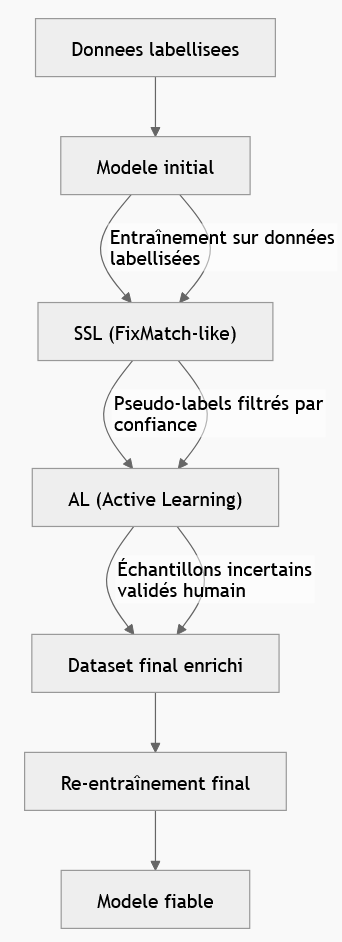